# BigMart Sales: Exploratory Data Analysis (EDA)

**Goal of the project:** predict `Item_Outlet_Sales` for 5,681 (product, store) pairs from 8,523 training pairs, scored by RMSE.
This notebook studies the data before and around the modelling. Every feature is examined on its own (**univariate**), against
sales and against the other features (**bivariate**), and together (**multivariate**). Each pattern is checked with a
**hypothesis test** before it is trusted.

**How to read it.** Each section says what is computed and why, shows the tables and plots, and ends with a short
**"What this shows"** in plain words. Unless a section says otherwise, only the train file is analysed. The test file is
used only to compare its features with train (section 11); test sales are never seen.

| Kind of analysis | Question it answers | Sections |
|---|---|---|
| Descriptive | What does the data look like? | 1 to 5 |
| Diagnostic | Why does sales behave this way, and is the pattern real? | 6 to 10 |
| Predictive | Which features can predict sales, and in what form? | 6, 7, 9, 10 |
| Prescriptive | What should the model do because of it? | 12 |

**Statistical tests used.** A p-value is the chance of seeing data at least this extreme if the null hypothesis
(H0, "no effect") were true. Below 0.05 counts as evidence against H0.

| Test | H0 (what it assumes) | Used for |
|---|---|---|
| Shapiro-Wilk, D'Agostino K², Jarque-Bera, Kolmogorov-Smirnov | the data are normally distributed | shape of each numeric column |
| Pearson r / Spearman ρ / Kendall τ | no linear / monotonic association | numeric feature vs sales |
| One-way ANOVA (F) / Kruskal-Wallis (H) | all group means / distributions are equal | category vs sales |
| Levene | all groups have the same spread | equal-variance check, fan shape |
| Welch t-test / Mann-Whitney U | two groups have the same mean / distribution | two-group comparisons |
| Tukey HSD | no pair of groups differs (post-hoc, corrected for many pairs) | which store types differ |
| Chi-square goodness of fit | all levels are equally common | frequencies, uniform MRP noise |
| Chi-square test of independence, Cramér's V | two categorical features are unrelated | category vs category |
| Nested (partial) F-test | the extra terms add nothing | interactions, feature blocks |
| Two-sample Kolmogorov-Smirnov | train and test come from the same distribution | train vs test |

## 0. Setup

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from src import config, data, models

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 85, "axes.titlesize": 11, "axes.labelsize": 10})
pd.set_option("display.max_columns", 60, "display.width", 180, "display.float_format", "{:,.3f}".format)

TARGET = config.TARGET
train, test = data.load_raw()
print(f"train: {train.shape[0]:,} rows x {train.shape[1]} columns | test: {test.shape[0]:,} rows x {test.shape[1]} columns")

train: 8,523 rows x 12 columns | test: 5,681 rows x 11 columns


In [2]:
def add_columns(df):
    """Columns derived from each row's own values (no statistics across rows)."""
    df = df.copy()
    df["Item_Category"] = df["Item_Identifier"].str[:2].map({"FD": "Food", "DR": "Drinks", "NC": "Non-Consumable"})
    df["ID_Letter"] = df["Item_Identifier"].str[2]
    df["ID_Number"] = df["Item_Identifier"].str[3:].astype(int)
    df["Outlet_Age"] = 2013 - df["Outlet_Establishment_Year"]
    fat = df["Item_Fat_Content"].replace({"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular"})
    df["Fat_Clean"] = fat.where(df["Item_Category"] != "Non-Consumable", "Non-Edible")
    df["MRP_Band"] = pd.cut(df["Item_MRP"], [0, 69, 136, 203, 400], labels=["<69", "69-136", "136-203", ">203"])
    return df


df, te = add_columns(train), add_columns(test)
# Weight is a fixed property of a product, so a missing weight is filled from the same product's other train rows.
df["Item_Weight_filled"] = df["Item_Weight"].fillna(df.groupby("Item_Identifier")["Item_Weight"].transform("mean"))

NUMERIC = ["Item_Weight", "Item_Visibility", "Item_MRP", "Outlet_Establishment_Year"]
CATEGORICAL = ["Item_Fat_Content", "Fat_Clean", "Item_Type", "Item_Category", "Outlet_Identifier",
               "Outlet_Size", "Outlet_Location_Type", "Outlet_Type", "ID_Letter"]
print("derived columns:", [c for c in df.columns if c not in train.columns])

derived columns: ['Item_Category', 'ID_Letter', 'ID_Number', 'Outlet_Age', 'Fat_Clean', 'MRP_Band', 'Item_Weight_filled']


In [3]:
def describe_numeric(s):
    """Every summary statistic of one numeric column (missing values dropped)."""
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "count": s.size, "mean": s.mean(), "median": s.median(), "mode": s.round(2).mode().iat[0],
        "std": s.std(), "variance": s.var(), "coef. of variation": s.std() / s.mean(),
        "min": s.min(), "Q1": q1, "Q3": q3, "IQR": q3 - q1, "max": s.max(), "range": s.max() - s.min(),
        "skewness": stats.skew(s), "excess kurtosis": stats.kurtosis(s),
    })


def normality_tests(s, seed=0):
    """p-values of four normality tests (H0: the values come from a normal distribution)."""
    s = s.dropna()
    sample = s.sample(min(len(s), 5000), random_state=seed)   # Shapiro-Wilk is designed for up to 5,000 values
    return pd.Series({
        "Shapiro-Wilk p": stats.shapiro(sample).pvalue,
        "D'Agostino K2 p": stats.normaltest(s).pvalue,
        "Jarque-Bera p": stats.jarque_bera(s).pvalue,
        "Kolmogorov-Smirnov p": stats.kstest((s - s.mean()) / s.std(), "norm").pvalue,
    })


def with_missing(s):
    """A categorical column as text, with missing values shown as their own level."""
    s = pd.Series(np.asarray(s, dtype=object))
    return s.where(s.notna(), "(missing)").astype(str)


def eta_squared(y, groups):
    """Share of the variance of y explained by the group means (0 = none, 1 = all)."""
    y, groups = pd.Series(np.asarray(y, dtype=float)), pd.Series(np.asarray(groups))
    means = y.groupby(groups).transform("mean")
    return float(((means - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum())


def group_tests(y, groups):
    """One-way ANOVA, Kruskal-Wallis and Levene across the groups, plus eta squared."""
    y, groups = pd.Series(np.asarray(y, dtype=float)), with_missing(groups)
    samples = [v.to_numpy() for _, v in y.groupby(groups) if len(v) > 1]
    anova, kruskal = stats.f_oneway(*samples), stats.kruskal(*samples)
    return pd.Series({
        "groups": len(samples), "ANOVA F": anova.statistic, "ANOVA p": anova.pvalue,
        "Kruskal-Wallis H": kruskal.statistic, "Kruskal-Wallis p": kruskal.pvalue,
        "Levene p": stats.levene(*samples).pvalue, "eta squared": eta_squared(y, groups),
    })


def cramers_v(a, b):
    """Strength of association between two categorical columns (0 = none, 1 = one determines the other)."""
    table = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n, (r, k) = table.to_numpy().sum(), table.shape
    return float(np.sqrt(chi2 / (n * (min(r, k) - 1))))


def ols_rss(X, y):
    """Residual sum of squares and number of free parameters of a least-squares fit."""
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    resid = y - X @ beta
    return float(resid @ resid), int(np.linalg.matrix_rank(X))

## 1. Data overview
What each column is, its type, how many distinct values it has, and how much is missing.

In [4]:
df[train.columns].head(8)

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016,Dairy,249.809,OUT049,1999,Medium,Tier 1,Supermarket Type1,"3,735.138"
1,DRC01,5.920,Regular,0.019,Soft Drinks,48.269,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.423
2,FDN15,17.500,Low Fat,0.017,Meat,141.618,OUT049,1999,Medium,Tier 1,Supermarket Type1,"2,097.270"
3,FDX07,19.200,Regular,0.000,Fruits and Vegetables,182.095,OUT010,1998,NaN,Tier 3,Grocery Store,732.380
4,NCD19,8.930,Low Fat,0.000,Household,53.861,OUT013,1987,High,Tier 3,Supermarket Type1,994.705
5,FDP36,10.395,Regular,0.000,Baking Goods,51.401,OUT018,2009,Medium,Tier 3,Supermarket Type2,556.609
6,FDO10,13.650,Regular,0.013,Snack Foods,57.659,OUT013,1987,High,Tier 3,Supermarket Type1,343.553
7,FDP10,NaN,Low Fat,0.127,Snack Foods,107.762,OUT027,1985,Medium,Tier 3,Supermarket Type3,"4,022.764"


In [5]:
kinds = {
    "Item_Identifier": "identifier: category (FD/DR/NC) + letter + number",
    "Item_Weight": "numeric, continuous (weight)",
    "Item_Fat_Content": "categorical, nominal",
    "Item_Visibility": "numeric, continuous (share of display area)",
    "Item_Type": "categorical, nominal (16 product types)",
    "Item_MRP": "numeric, continuous (list price)",
    "Outlet_Identifier": "categorical, nominal (10 stores)",
    "Outlet_Establishment_Year": "numeric, discrete (opening year)",
    "Outlet_Size": "categorical, ordinal (Small < Medium < High)",
    "Outlet_Location_Type": "categorical, ordinal (Tier 1 / 2 / 3)",
    "Outlet_Type": "categorical, nominal (grocery store or supermarket type)",
    TARGET: "numeric, continuous: THE TARGET",
}
pd.DataFrame({
    "kind": pd.Series(kinds),
    "dtype": train.dtypes.astype(str),
    "unique values": train.nunique(),
    "missing": train.isna().sum(),
    "missing %": train.isna().mean() * 100,
    "first row": train.iloc[0].astype(str),
}).reindex(train.columns)

,kind,dtype,unique values,missing,missing %,first row
Item_Identifier,identifier: category (FD/DR/NC) + letter + number,str,1559,0,0.000,FDA15
Item_Weight,"numeric, continuous (weight)",float64,415,1463,17.165,9.3
Item_Fat_Content,"categorical, nominal",str,5,0,0.000,Low Fat
Item_Visibility,"numeric, continuous (share of display area)",float64,7880,0,0.000,0.016047301
Item_Type,"categorical, nominal (16 product types)",str,16,0,0.000,Dairy
Item_MRP,"numeric, continuous (list price)",float64,5938,0,0.000,249.8092
Outlet_Identifier,"categorical, nominal (10 stores)",str,10,0,0.000,OUT049
Outlet_Establishment_Year,"numeric, discrete (opening year)",int64,9,0,0.000,1999
Outlet_Size,"categorical, ordinal (Small < Medium < High)",str,3,2410,28.276,Medium
Outlet_Location_Type,"categorical, ordinal (Tier 1 / 2 / 3)",str,3,0,0.000,Tier 1


**What this shows:** 12 columns.
- **Product side:** id, weight, fat content, visibility, type, MRP.
- **Store side:** id, opening year, size, location tier, type.
- **Plus the target:** sales.

Two columns have gaps: `Item_Weight` (17%) and `Outlet_Size` (28%). The unique counts hold two hints:
- **Sales has only 3,493 distinct values in 8,523 rows.** A continuous quantity almost never repeats like that; this is the first hint of the hidden price grid in section 10.2.
- **`Item_Weight` has only 415 values for 1,559 products.** Weight is a product property, and many products share one.

## 2. Data quality
Problems to know about before analysing: missing values, duplicates, inconsistent labels, impossible values,
whether a product looks the same in every store, and outliers.

### 2.1 Missing values: how many, and where

,train missing,train %,test missing,test %
Item_Weight,1463,17.165,976.000,17.180
Outlet_Size,2410,28.276,"1,606.000",28.270


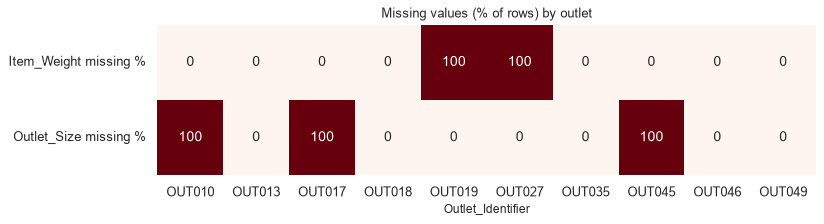

In [6]:
missing = pd.DataFrame({
    "train missing": train.isna().sum(), "train %": train.isna().mean() * 100,
    "test missing": test.isna().sum(), "test %": test.isna().mean() * 100,
}).reindex(train.columns)
display(missing[missing["train missing"] > 0])

by_outlet = pd.DataFrame({
    "Item_Weight missing %": df["Item_Weight"].isna().groupby(df["Outlet_Identifier"]).mean() * 100,
    "Outlet_Size missing %": df["Outlet_Size"].isna().groupby(df["Outlet_Identifier"]).mean() * 100,
})
fig, ax = plt.subplots(figsize=(10, 2.3))
sns.heatmap(by_outlet.T, annot=True, fmt=".0f", cmap="Reds", cbar=False, ax=ax)
ax.set_title("Missing values (% of rows) by outlet")
plt.show()

**What this shows:** the gaps are not random rows.
- `Item_Weight` is missing for **every** row of stores OUT019 and OUT027, and nowhere else.
- `Outlet_Size` is missing for three whole stores: OUT010, OUT017 and OUT045.
- The test file has exactly the same pattern (17.2% and 28.3%).

**Fixes:**
- **Weight:** fill it from the same product's rows in other stores. Weight is a fixed product property; 2.5 shows it never changes within a product.
- **Size:** it isn't needed, because the store's own identity carries all store information (sections 7 and 8).

### 2.2 Duplicates and keys

In [7]:
pairs = train[["Item_Identifier", "Outlet_Identifier"]]
rows_per_item = train.groupby("Item_Identifier").size()
shared = set(map(tuple, pairs.to_numpy())) & set(map(tuple, test[pairs.columns].to_numpy()))
print(f"duplicate rows: {train.duplicated().sum()}")
print(f"duplicate (item, outlet) pairs: {pairs.duplicated().sum()}  -> each row is one product in one store")
print(f"products: {train.Item_Identifier.nunique():,}   outlets: {train.Outlet_Identifier.nunique()}")
print(f"train rows per product: mean {rows_per_item.mean():.2f}, min {rows_per_item.min()}, max {rows_per_item.max()}")
print(f"test products that also appear in train: {test.Item_Identifier.isin(train.Item_Identifier).mean():.0%}")
print(f"(item, outlet) pairs present in both train and test: {len(shared)}")

duplicate rows: 0
duplicate (item, outlet) pairs: 0  -> each row is one product in one store
products: 1,559   outlets: 10
train rows per product: mean 5.47, min 1, max 10
test products that also appear in train: 100%
(item, outlet) pairs present in both train and test: 0


**What this shows:**
- **No duplicates:** each row is one product in one store.
- **Coverage:** a product appears in 1 to 10 stores (5.5 on average in train).
- **Test vs train:** every test product also appears in train, but no (product, store) pair appears in both. The test asks about known products in stores where we have not seen them sell.

### 2.3 Inconsistent labels

In [8]:
print("Item_Fat_Content as written (5 spellings for 2 values):")
display(df["Item_Fat_Content"].value_counts().to_frame("rows").T)
print("Fat label by product category: non-consumables (NC) carry a fat label, which makes no sense:")
display(pd.crosstab(df["Item_Fat_Content"], df["Item_Category"]))

Item_Fat_Content as written (5 spellings for 2 values):


Item_Fat_Content,Low Fat,Regular,LF,reg,low fat
rows,5089,2889,316,117,112


Fat label by product category: non-consumables (NC) carry a fat label, which makes no sense:


Item_Category,Drinks,Food,Non-Consumable
Item_Fat_Content,,,
LF,39,183,94
Low Fat,671,2941,1477
Regular,70,2819,0
low fat,18,66,28
reg,1,116,0


**What this shows:**
- **Five spellings:** `Item_Fat_Content` writes 2 values 5 ways (LF and low fat mean Low Fat; reg means Regular). They are merged in `Fat_Clean`.
- **Nonsense labels:** all 1,599 non-consumable rows (household and health products) are labelled Low Fat or LF. In `Fat_Clean` they become **Non-Edible**.

### 2.4 Impossible values: zero visibility

In [9]:
zero = df["Item_Visibility"].eq(0)
print(f"rows with Item_Visibility = 0: {zero.sum()} ({zero.mean():.1%})")
display((zero.groupby(df["Outlet_Identifier"]).mean() * 100).to_frame("% of rows with zero visibility").T)

rows with Item_Visibility = 0: 526 (6.2%)


Outlet_Identifier,OUT010,OUT013,OUT017,OUT018,OUT019,OUT027,OUT035,OUT045,OUT046,OUT049
% of rows with zero visibility,5.225,6.330,6.156,7.004,5.682,6.417,5.806,6.243,6.559,5.699


**What this shows:** 526 rows (6.2%) have zero visibility, which is impossible for a product on sale.
- They are spread evenly over all stores (5% to 7% each), which points to random recording errors.
- Section 7 shows these rows sell the same as the rest (p = 0.58), so they carry no special meaning.

### 2.5 Does the same product look the same in every store?

In [10]:
within = df.groupby("Item_Identifier").agg(
    weight_sd=("Item_Weight", "std"), item_types=("Item_Type", "nunique"), fat_labels=("Fat_Clean", "nunique"),
    mrp_sd=("Item_MRP", "std"), mrp_range=("Item_MRP", lambda s: s.max() - s.min()),
    visibility_sd=("Item_Visibility", "std"))
within.describe().loc[["mean", "min", "50%", "max"]]

,weight_sd,item_types,fat_labels,mrp_sd,mrp_range,visibility_sd
mean,0.000,1.000,1.000,1.145,2.752,0.018
min,0.000,1.000,1.000,0.058,0.000,0.000
50%,0.000,1.000,1.000,1.161,2.900,0.011
max,0.000,1.000,1.000,2.546,4.000,0.118


**What this shows:**
- **Fixed per product:** weight, item type and fat label never change within a product. They are product properties.
- **Varies by store:** visibility differs from store to store, as shelf space would.
- **The surprise:** the listed price (MRP) of the *same* product also differs between stores, by up to **exactly 4.0** (±2). Section 10.2 shows this is deliberate noise around one true price.

### 2.6 Outliers (IQR rule and z-scores)

In [11]:
rows = []
for col in NUMERIC + [TARGET]:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    rows.append({"feature": col, "lower fence": low, "upper fence": high,
                 "below fence": int((s < low).sum()), "above fence": int((s > high).sum()),
                 "|z| > 3": int((np.abs(stats.zscore(s)) > 3).sum())})
pd.DataFrame(rows).set_index("feature")

,lower fence,upper fence,below fence,above fence,|z| > 3
feature,,,,,
Item_Weight,-3.341,28.964,0,0,0
Item_Visibility,-0.074,0.196,0,144,95
Item_MRP,-43.899,323.370,0,0,0
Outlet_Establishment_Year,"1,961.500","2,029.500",0,0,0
Item_Outlet_Sales,"-2,566.326","6,501.870",0,186,90


**What this shows:**
- **Visibility:** 144 rows sit above the upper fence. That is its long right tail: a few products get a large shelf share.
- **Sales:** 186 rows exceed 6,502 (90 beyond 3 standard deviations). These are real large sales, mostly expensive products in the biggest store (OUT027), not errors. Capping them was tested and did not help, because RMSE is scored on exactly these values.
- **Weight, MRP and year:** no outliers.

## 3. Univariate analysis: the target `Item_Outlet_Sales`
Every summary statistic, the shape (skewness, kurtosis), four normality tests, and the same for log and square-root
transforms.

In [12]:
sales = df[TARGET]
transforms = {"sales": sales, "log(sales)": np.log(sales), "sqrt(sales)": np.sqrt(sales)}
pd.concat({name: pd.concat([describe_numeric(s), normality_tests(s)]) for name, s in transforms.items()}, axis=1)

,sales,log(sales),sqrt(sales)
count,"8,523.000","8,523.000","8,523.000"
mean,"2,181.289",7.297,42.945
median,"1,794.331",7.492,42.360
mode,958.750,7.650,30.960
std,"1,706.500",1.017,18.360
variance,"2,912,140.938",1.035,337.075
coef. of variation,0.782,0.139,0.428
min,33.290,3.505,5.770
Q1,834.247,6.727,28.883
Q3,"3,101.296",8.040,55.689


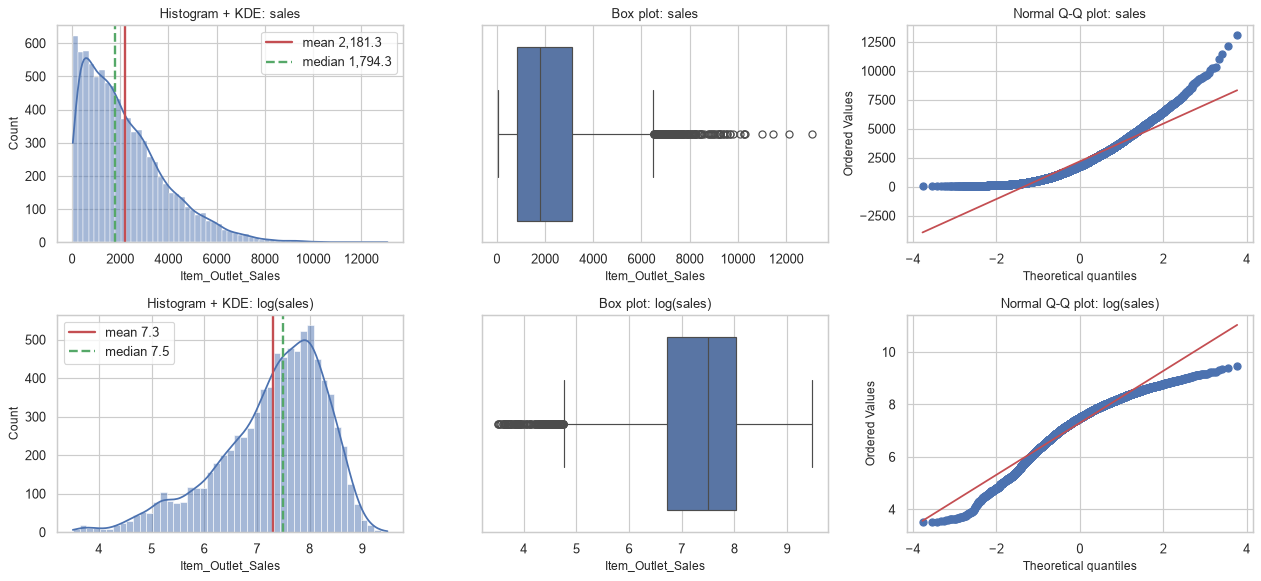

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for row, (name, s) in enumerate([("sales", sales), ("log(sales)", np.log(sales))]):
    sns.histplot(s, kde=True, ax=axes[row, 0], color="C0")
    axes[row, 0].axvline(s.mean(), color="C3", lw=2, label=f"mean {s.mean():,.1f}")
    axes[row, 0].axvline(s.median(), color="C2", lw=2, ls="--", label=f"median {s.median():,.1f}")
    axes[row, 0].legend(); axes[row, 0].set_title(f"Histogram + KDE: {name}")
    sns.boxplot(x=s, ax=axes[row, 1], color="C0"); axes[row, 1].set_title(f"Box plot: {name}")
    stats.probplot(s, dist="norm", plot=axes[row, 2]); axes[row, 2].set_title(f"Normal Q-Q plot: {name}")
plt.tight_layout(); plt.show()

**What this shows:**
- **Average vs typical:** average sales are 2,181, but the median (1,794) is lower. A long right tail of large sales pulls the mean up (skewness 1.18, excess kurtosis 1.61).
- **Spread:** sales vary a lot (standard deviation 1,707, coefficient of variation 0.78).
- **Not normal:** all four tests reject normality (p ≈ 0), and the Q-Q plot bends up at the right end.
- **Transforms:** log over-corrects into a left skew (-0.89); the square root is the most symmetric (0.24).
- **The mode** (958.75) is the most-repeated exact value, again a hint of the price grid.

**Decision:** the score (RMSE) is on raw sales, so the models predict raw sales. Models with a log *link* (GLMs) still capture the multiplicative shape without transforming the target. Training on log(sales) was tested and was worse.

## 4. Univariate analysis: numeric features
The same statistics and plots for `Item_Weight`, `Item_Visibility`, `Item_MRP` and `Outlet_Establishment_Year`.

In [14]:
pd.concat({col: pd.concat([describe_numeric(df[col]), normality_tests(df[col]),
                           pd.Series({"missing": df[col].isna().sum(), "zeros": int((df[col] == 0).sum())})])
           for col in NUMERIC}, axis=1)

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year
count,"7,060.000","8,523.000","8,523.000","8,523.000"
mean,12.858,0.066,140.993,"1,997.832"
median,12.600,0.054,143.013,"1,999.000"
mode,12.150,0.030,196.510,"1,985.000"
std,4.643,0.052,62.275,8.372
variance,21.562,0.003,"3,878.184",70.086
coef. of variation,0.361,0.780,0.442,0.004
min,4.555,0.000,31.290,"1,985.000"
Q1,8.774,0.027,93.826,"1,987.000"
Q3,16.850,0.095,185.644,"2,004.000"


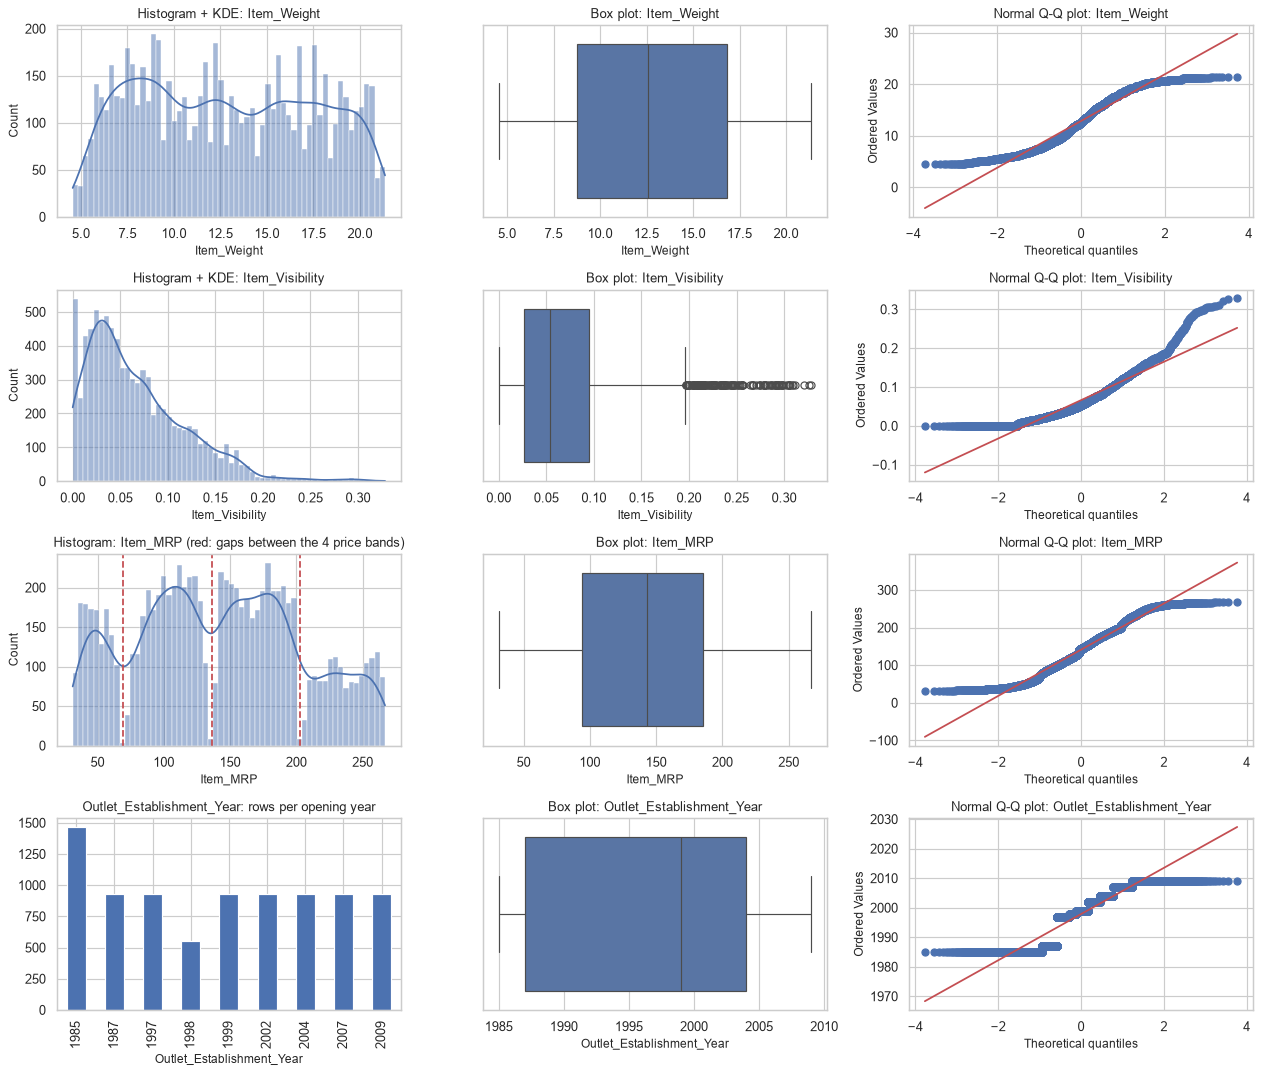

In [15]:
fig, axes = plt.subplots(len(NUMERIC), 3, figsize=(15, 3.2 * len(NUMERIC)))
for row, col in enumerate(NUMERIC):
    s = df[col].dropna()
    if col == "Outlet_Establishment_Year":
        s.value_counts().sort_index().plot.bar(ax=axes[row, 0], color="C0")
        axes[row, 0].set_title(f"{col}: rows per opening year")
    else:
        sns.histplot(s, kde=True, ax=axes[row, 0], color="C0", bins=60)
        axes[row, 0].set_title(f"Histogram + KDE: {col}")
    if col == "Item_MRP":
        for edge in (69, 136, 203):
            axes[row, 0].axvline(edge, color="C3", ls="--")
        axes[row, 0].set_title("Histogram: Item_MRP (red: gaps between the 4 price bands)")
    sns.boxplot(x=s, ax=axes[row, 1], color="C0"); axes[row, 1].set_title(f"Box plot: {col}")
    stats.probplot(s, dist="norm", plot=axes[row, 2]); axes[row, 2].set_title(f"Normal Q-Q plot: {col}")
plt.tight_layout(); plt.show()

**What this shows:**
- **`Item_Weight`:** spread almost evenly between 4.6 and 21.4 (flat: excess kurtosis -1.23, no skew), with no outliers.
- **`Item_Visibility`:** right-skewed (1.17), with 526 impossible zeros.
- **`Item_MRP`:** symmetric but split into **four separate price bands** (gaps near 69, 136 and 203). The bands come from how products were priced.
- **`Outlet_Establishment_Year`:** only 9 values, one per store opening. 1985 holds two stores (OUT019 and OUT027).
- **Normality:** all four tests reject it for every feature (p ≈ 0). That is fine: no model here assumes normal features.

## 5. Univariate analysis: categorical features
For every categorical feature: how many levels, the most and least common, and a chi-square goodness-of-fit test of
"all levels are equally common". Then the frequency tables and a bar chart for each.

In [16]:
summary = []
for col in CATEGORICAL + ["Outlet_Establishment_Year", "MRP_Band", "ID_Number"]:
    counts = with_missing(df[col]).value_counts()
    gof = stats.chisquare(counts.to_numpy())
    summary.append({"feature": col, "levels": counts.size, "mode": counts.index[0], "mode share": counts.iat[0] / counts.sum(),
                    "rarest level": counts.index[-1], "rarest share": counts.iat[-1] / counts.sum(),
                    "chi-square (equal shares)": gof.statistic, "p": gof.pvalue})
pd.DataFrame(summary).set_index("feature")

,levels,mode,mode share,rarest level,rarest share,chi-square (equal shares),p
feature,,,,,,,
Item_Fat_Content,5,Low Fat,0.597,low fat,0.013,"11,640.282",0.000
Fat_Clean,3,Low Fat,0.460,Non-Edible,0.188,960.830,0.000
Item_Type,16,Fruits and Vegetables,0.145,Seafood,0.008,"3,959.735",0.000
Item_Category,3,Food,0.719,Drinks,0.094,"5,806.753",0.000
Outlet_Identifier,10,OUT027,0.110,OUT019,0.062,283.827,0.000
Outlet_Size,4,Medium,0.328,High,0.109,947.899,0.000
Outlet_Location_Type,3,Tier 3,0.393,Tier 1,0.280,164.529,0.000
Outlet_Type,4,Supermarket Type1,0.654,Supermarket Type2,0.109,"7,439.092",0.000
ID_Letter,26,X,0.042,M,0.035,11.354,0.991


In [17]:
for col in ["Item_Type", "Outlet_Identifier", "Outlet_Type", "Outlet_Size", "Outlet_Location_Type", "Fat_Clean", "Item_Category"]:
    counts = df[col].fillna("(missing)").value_counts()
    display(pd.DataFrame({"rows": counts, "share %": counts / counts.sum() * 100}).T.rename_axis(col, axis=1))

Item_Type,Fruits and Vegetables,Snack Foods,Household,Frozen Foods,Dairy,Canned,Baking Goods,Health and Hygiene,Soft Drinks,Meat,Breads,Hard Drinks,Others,Starchy Foods,Breakfast,Seafood
rows,"1,232.000","1,200.000",910.000,856.000,682.000,649.000,648.000,520.000,445.000,425.000,251.000,214.000,169.000,148.000,110.000,64.000
share %,14.455,14.080,10.677,10.043,8.002,7.615,7.603,6.101,5.221,4.987,2.945,2.511,1.983,1.736,1.291,0.751


Outlet_Identifier,OUT027,OUT013,OUT049,OUT046,OUT035,OUT045,OUT018,OUT017,OUT010,OUT019
rows,935.000,932.000,930.000,930.000,930.000,929.000,928.000,926.000,555.000,528.000
share %,10.970,10.935,10.912,10.912,10.912,10.900,10.888,10.865,6.512,6.195


Outlet_Type,Supermarket Type1,Grocery Store,Supermarket Type3,Supermarket Type2
rows,"5,577.000","1,083.000",935.000,928.000
share %,65.435,12.707,10.970,10.888


Outlet_Size,Medium,(missing),Small,High
rows,"2,793.000","2,410.000","2,388.000",932.000
share %,32.770,28.276,28.018,10.935


Outlet_Location_Type,Tier 3,Tier 2,Tier 1
rows,"3,350.000","2,785.000","2,388.000"
share %,39.305,32.676,28.018


Fat_Clean,Low Fat,Regular,Non-Edible
rows,"3,918.000","3,006.000","1,599.000"
share %,45.970,35.269,18.761


Item_Category,Food,Non-Consumable,Drinks
rows,"6,125.000","1,599.000",799.000
share %,71.864,18.761,9.375


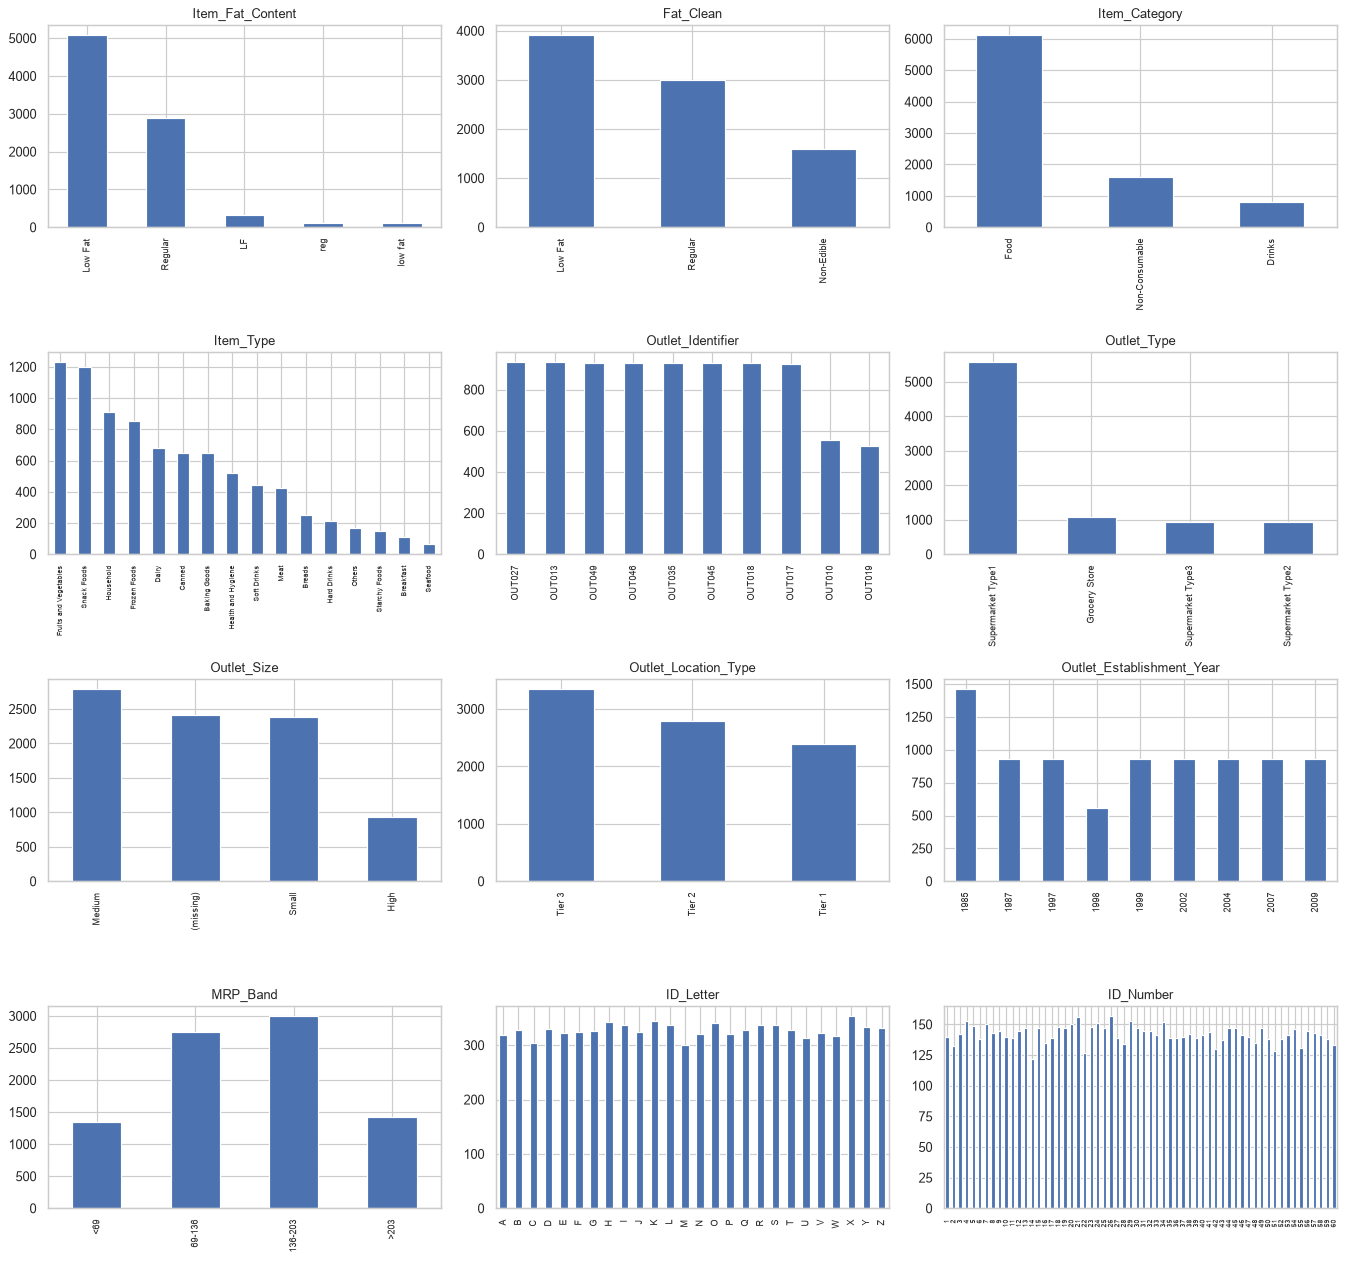

In [18]:
panels = ["Item_Fat_Content", "Fat_Clean", "Item_Category", "Item_Type", "Outlet_Identifier", "Outlet_Type",
          "Outlet_Size", "Outlet_Location_Type", "Outlet_Establishment_Year", "MRP_Band", "ID_Letter", "ID_Number"]
fig, axes = plt.subplots(4, 3, figsize=(16, 15))
for ax, col in zip(axes.ravel(), panels):
    if col == "MRP_Band":
        counts = df[col].value_counts().reindex(df[col].cat.categories)
    else:
        counts = with_missing(df[col]).value_counts()
        if col in ("ID_Number", "ID_Letter", "Outlet_Establishment_Year"):
            counts = counts.sort_index(key=lambda idx: idx.map(lambda v: (len(v), v)))
    counts.plot.bar(ax=ax, color="C0")
    ax.set_title(col); ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=6 if col in ("ID_Number", "Item_Type") else 8)
plt.tight_layout(); plt.show()

**What this shows:**
- **Stores:**
  - Eight stores have about 930 rows each. The two grocery stores have about 540, because they stock fewer products.
  - Type1 supermarkets hold 65% of rows.
  - The equal-shares test rejects for every store feature (p ≈ 0) because of this unevenness.
  - `Outlet_Size` is missing for 28% of rows (three whole stores).
- **Products:**
  - 72% food, 19% non-consumable, 9% drinks.
  - The 16 item types range from 14.5% (fruits and vegetables) to 0.8% (seafood).
- **The id:** its letter (A to Z, χ² p = 0.99) and its number (1 to 60, p = 1.00) are spread **perfectly evenly**, as expected from codes assigned systematically.
- **Price:** the 136–203 band is the most common.

## 6. Bivariate analysis: numeric features vs sales
Three correlation coefficients with p-values:
- **Pearson** measures straight-line association.
- **Spearman** and **Kendall** measure any steady rise or fall, using ranks.

Then a scatter plot for each feature, with the mean of 20 equal-size bins, and a check of whether the spread of sales
grows with price.

In [19]:
numeric_x = ["Item_MRP", "Item_Visibility", "Item_Weight", "Outlet_Age", "ID_Number"]
rows = []
for col in numeric_x:
    d = df[[col, TARGET]].dropna()
    pearson, spearman, kendall = stats.pearsonr(d[col], d[TARGET]), stats.spearmanr(d[col], d[TARGET]), stats.kendalltau(d[col], d[TARGET])
    rows.append({"feature": col, "Pearson r": pearson.statistic, "Pearson p": pearson.pvalue,
                 "Spearman rho": spearman.statistic, "Spearman p": spearman.pvalue,
                 "Kendall tau": kendall.statistic, "Kendall p": kendall.pvalue, "r squared": pearson.statistic ** 2})
pd.DataFrame(rows).set_index("feature")

,Pearson r,Pearson p,Spearman rho,Spearman p,Kendall tau,Kendall p,r squared
feature,,,,,,,
Item_MRP,0.568,0.000,0.563,0.000,0.407,0.000,0.322
Item_Visibility,-0.129,0.000,-0.115,0.000,-0.077,0.000,0.017
Item_Weight,0.014,0.235,0.015,0.206,0.010,0.215,0.000
Outlet_Age,0.049,0.000,-0.043,0.000,-0.031,0.000,0.002
ID_Number,0.023,0.031,0.022,0.038,0.015,0.037,0.001


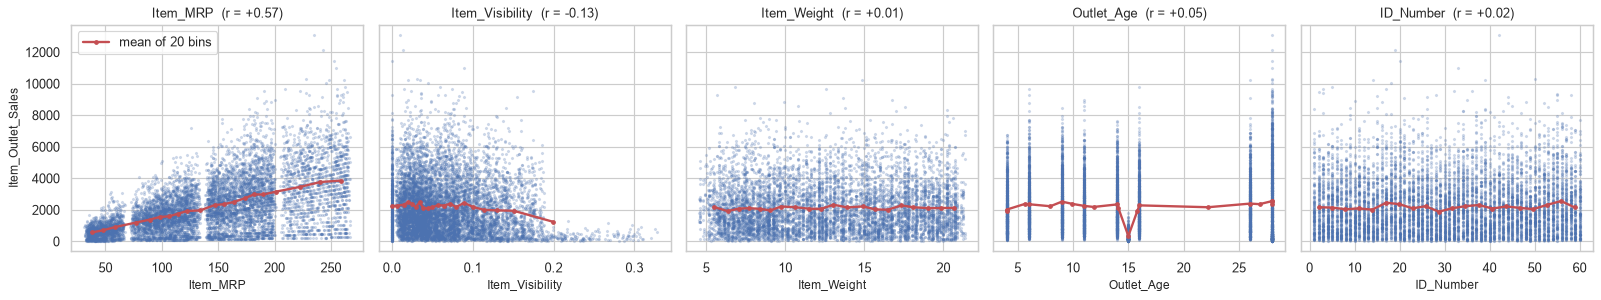

In [20]:
fig, axes = plt.subplots(1, len(numeric_x), figsize=(19, 3.7), sharey=True)
for ax, col in zip(axes, numeric_x):
    d = df[[col, TARGET]].dropna()
    ax.scatter(d[col], d[TARGET], s=3, alpha=0.2, color="C0")
    bins = pd.qcut(d[col].rank(method="first"), 20, labels=False)
    binned = d.groupby(bins).agg(x=(col, "mean"), y=(TARGET, "mean"))
    ax.plot(binned.x, binned.y, color="C3", lw=2, marker="o", ms=3, label="mean of 20 bins")
    ax.set_title(f"{col}  (r = {d[col].corr(d[TARGET]):+.2f})"); ax.set_xlabel(col)
axes[0].set_ylabel(TARGET); axes[0].legend()
plt.tight_layout(); plt.show()

,rows,mean,std,coef. of variation
MRP_Band,,,,
<69,1341,736.475,492.896,0.669
69-136,2751,"1,615.644","1,002.563",0.621
136-203,3002,"2,631.226","1,611.090",0.612
>203,1429,"3,680.849","2,123.228",0.577


Levene test (H0: sales have the same spread in every price band): W = 704.7, p = 0.0e+00


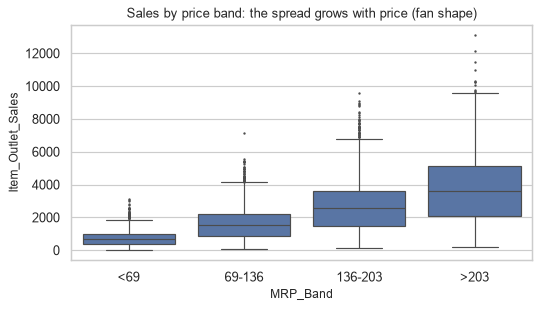

In [21]:
band = df.groupby("MRP_Band", observed=True)[TARGET].agg(rows="size", mean="mean", std="std")
band["coef. of variation"] = band["std"] / band["mean"]
display(band)
levene = stats.levene(*[g[TARGET].to_numpy() for _, g in df.groupby("MRP_Band", observed=True)])
print(f"Levene test (H0: sales have the same spread in every price band): W = {levene.statistic:.1f}, p = {levene.pvalue:.1e}")
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.boxplot(data=df, x="MRP_Band", y=TARGET, ax=ax, color="C0", fliersize=1)
ax.set_title("Sales by price band: the spread grows with price (fan shape)")
plt.show()

**What this shows:**
- **`Item_MRP`** is the strongest single driver (r = 0.57: it explains 32% of sales on its own).
- **`Item_Visibility`** has a weak negative link (r = -0.13).
- **`Item_Weight`** has none (p = 0.24).
- **`Outlet_Age`** even flips sign between Pearson (+0.05) and Spearman (-0.04). Age only stands in for the store: the oldest year holds both the biggest store (OUT027) and a grocery store (OUT019).
- **`ID_Number`** looks unrelated (r = 0.02), because its real effect is a **wave**, which a straight-line correlation cannot see (section 10.3).
- **The fan shape:** the spread of sales grows with price (standard deviation 493 → 2,123 across bands; Levene p ≈ 0), while the spread *relative to the mean* stays near 0.6.

**Decision:** errors are proportional to the size of the sale. That favours multiplicative (log-link) models, and weighting rows by price.

## 7. Bivariate analysis: categorical features vs sales
For every categorical feature:
- **One-way ANOVA:** do the group means differ?
- **Kruskal-Wallis:** the same question without assuming normality.
- **Levene:** do the groups differ in spread?
- **η² (eta squared):** the share of sales variance the feature explains.

Then box plots for each feature, two-group tests, and a Tukey post-hoc test for the store types.

In [22]:
pd.DataFrame({col: group_tests(df[TARGET], df[col]) for col in CATEGORICAL + ["Outlet_Establishment_Year", "MRP_Band"]}).T.sort_values("eta squared", ascending=False)

,groups,ANOVA F,ANOVA p,Kruskal-Wallis H,Kruskal-Wallis p,Levene p,eta squared
MRP_Band,4.000,"1,229.987",0.000,"2,626.895",0.000,0.000,0.302
Outlet_Identifier,10.000,300.079,0.000,"2,814.459",0.000,0.000,0.241
Outlet_Type,4.000,894.650,0.000,"2,803.361",0.000,0.000,0.240
Outlet_Establishment_Year,9.000,102.573,0.000,"1,232.656",0.000,0.000,0.088
Outlet_Size,4.000,143.657,0.000,461.136,0.000,0.000,0.048
Outlet_Location_Type,3.000,53.948,0.000,155.506,0.000,0.000,0.013
ID_Letter,26.000,2.286,0.000,59.485,0.000,0.003,0.007
Item_Type,16.000,2.701,0.000,41.200,0.000,0.005,0.005
Item_Category,3.000,6.279,0.002,12.890,0.002,0.015,0.001
Item_Fat_Content,5.000,1.726,0.141,6.072,0.194,0.237,0.001


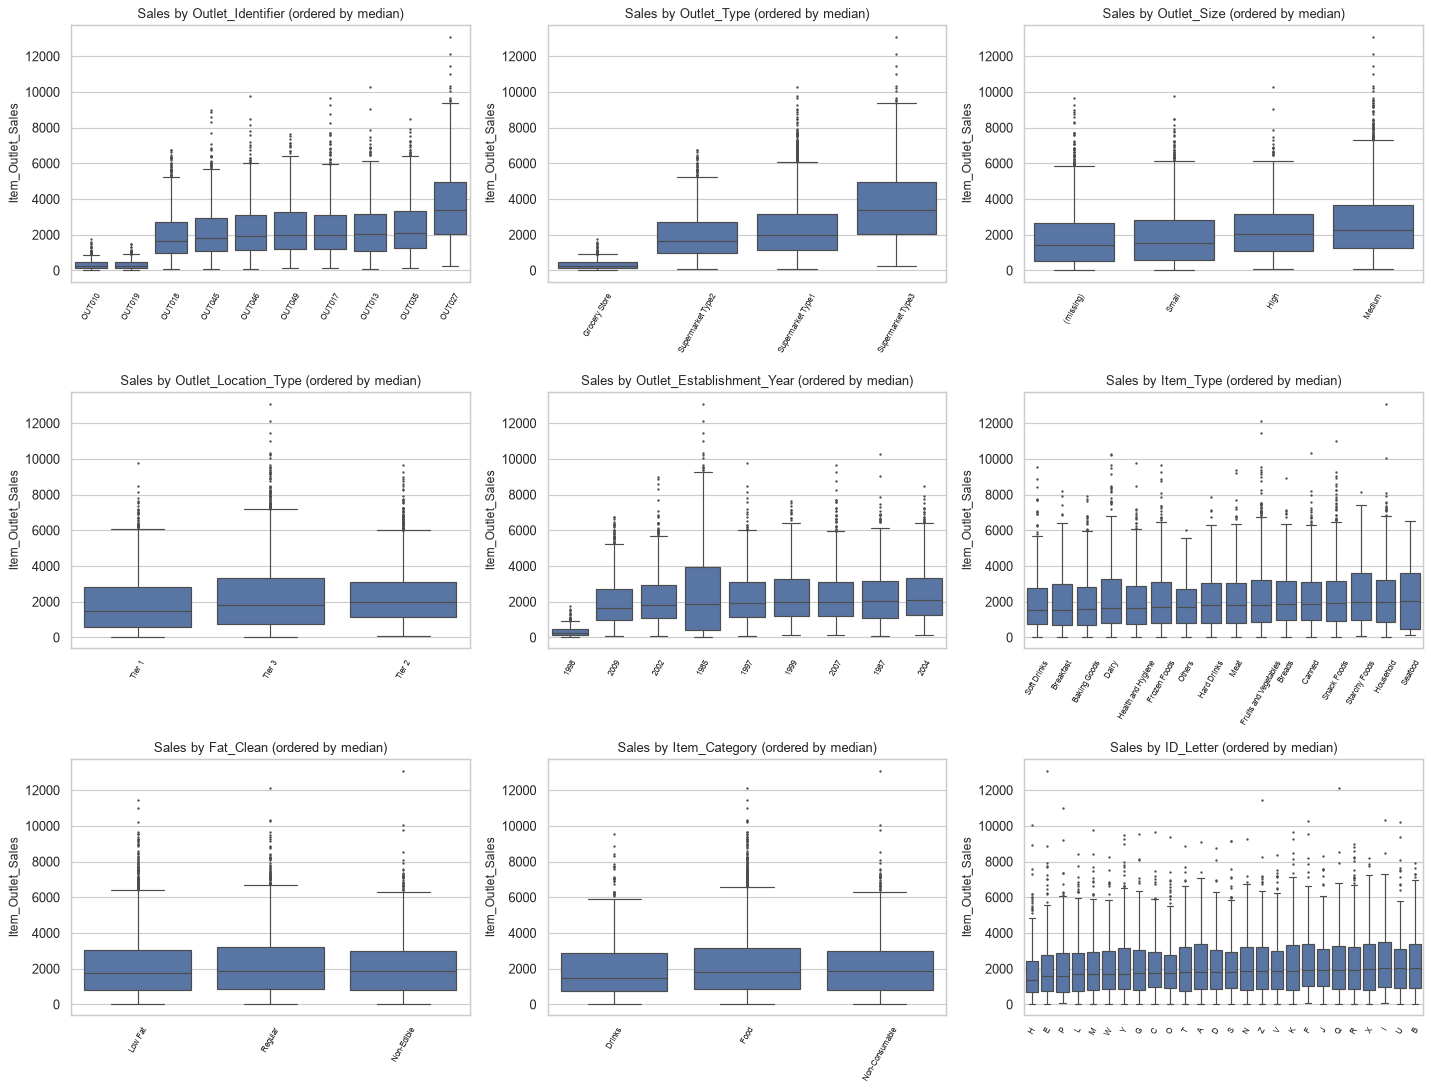

In [23]:
panels = ["Outlet_Identifier", "Outlet_Type", "Outlet_Size", "Outlet_Location_Type", "Outlet_Establishment_Year",
          "Item_Type", "Fat_Clean", "Item_Category", "ID_Letter"]
fig, axes = plt.subplots(3, 3, figsize=(17, 13))
for ax, col in zip(axes.ravel(), panels):
    d = df.assign(**{col: with_missing(df[col]).to_numpy()})
    order = d.groupby(col)[TARGET].median().sort_values().index
    sns.boxplot(data=d, x=col, y=TARGET, order=order, ax=ax, color="C0", fliersize=1)
    ax.set_title(f"Sales by {col} (ordered by median)"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60, labelsize=7)
plt.tight_layout(); plt.show()

In [24]:
def two_groups(a, b, label):
    welch, mann_whitney = stats.ttest_ind(a, b, equal_var=False), stats.mannwhitneyu(a, b)
    print(f"{label}: means {a.mean():,.1f} vs {b.mean():,.1f} | Welch t = {welch.statistic:.2f}, p = {welch.pvalue:.3g}"
          f" | Mann-Whitney U p = {mann_whitney.pvalue:.3g}")


edible = df[df["Fat_Clean"] != "Non-Edible"]
two_groups(edible.loc[edible.Fat_Clean == "Low Fat", TARGET], edible.loc[edible.Fat_Clean == "Regular", TARGET], "Low Fat vs Regular")
grocery = df["Outlet_Type"] == "Grocery Store"
two_groups(df.loc[grocery, TARGET], df.loc[~grocery, TARGET], "Grocery stores vs supermarkets")
zero = df["Item_Visibility"] == 0
two_groups(df.loc[zero, TARGET], df.loc[~zero, TARGET], "Zero visibility vs the rest")

types = sorted(df["Outlet_Type"].unique())
tukey = stats.tukey_hsd(*[df.loc[df.Outlet_Type == t, TARGET].to_numpy() for t in types])
pairs = [(types[i], types[j], tukey.statistic[i, j], tukey.pvalue[i, j]) for i in range(len(types)) for j in range(i + 1, len(types))]
print("\nTukey HSD post-hoc test on Outlet_Type (which pairs of store types differ?):")
pd.DataFrame(pairs, columns=["type A", "type B", "mean difference (A - B)", "p"])

Low Fat vs Regular: means 2,163.8 vs 2,224.6 | Welch t = -1.45, p = 0.146 | Mann-Whitney U p = 0.0731
Grocery stores vs supermarkets: means 339.8 vs 2,449.3 | Welch t = -101.27, p = 0 | Mann-Whitney U p = 0
Zero visibility vs the rest: means 2,222.5 vs 2,178.6 | Welch t = 0.56, p = 0.575 | Mann-Whitney U p = 0.613

Tukey HSD post-hoc test on Outlet_Type (which pairs of store types differ?):


,type A,type B,mean difference (A - B),p
0,Grocery Store,Supermarket Type1,"-1,976.353",0.000
1,Grocery Store,Supermarket Type2,"-1,655.670",0.000
2,Grocery Store,Supermarket Type3,"-3,354.210",0.000
3,Supermarket Type1,Supermarket Type2,320.682,0.000
4,Supermarket Type1,Supermarket Type3,"-1,377.857",0.000
5,Supermarket Type2,Supermarket Type3,"-1,698.540",0.000


**What this shows:**
- **The store explains most of the variation:**
  - Outlet identity has η² = 0.24, i.e. 24% of the variance in sales; store type alone also has 0.24.
  - Size, location and opening year are weaker versions of the same store information.
  - Price band explains the most (0.30), as in section 6.
- **Grocery stores** sell about a seventh of what supermarkets sell (340 vs 2,449; Welch t = -101).
- **Tukey's post-hoc test:** every pair of store types differs (all p ≈ 0), in the order Type3 > Type1 > Type2 > Grocery.
- **Product features matter almost nothing:**
  - Fat content: Low Fat vs Regular p = 0.15.
  - Zero visibility: p = 0.58.
  - Item type, category and letter are 'significant' on raw sales but explain under 1%. Section 10.4 shows even that disappears once store and price are accounted for: it was **confounding** (some types are simply pricier).
- **Levene rejects equal spread** for the store features: bigger stores have bigger swings.

## 8. Bivariate analysis: features vs each other
- **Numeric vs numeric:** Pearson and Spearman correlation matrices.
- **Categorical vs categorical:** Cramér's V with chi-square tests of independence.
- **Numeric vs categorical:** η² with ANOVA.

This shows which features carry the same information (redundancy) and which are nested inside others.

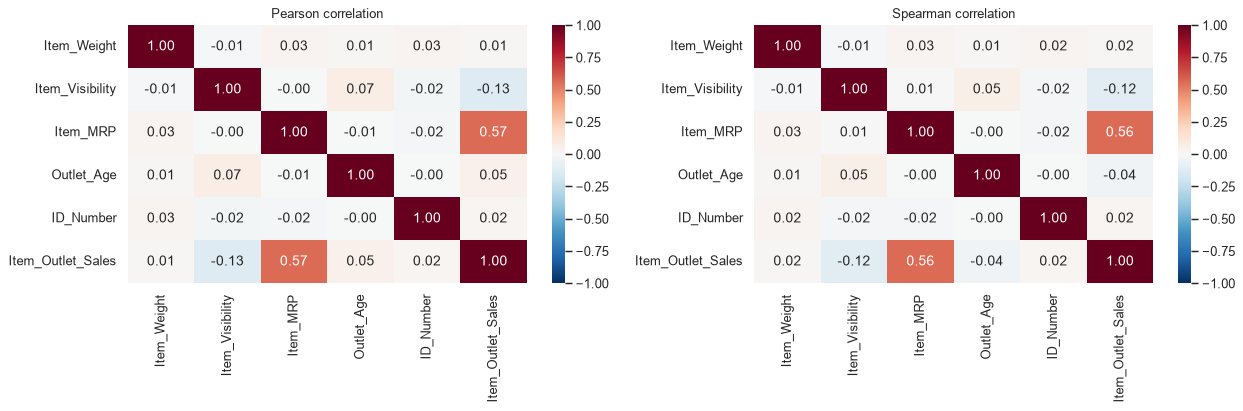

In [25]:
cols = ["Item_Weight", "Item_Visibility", "Item_MRP", "Outlet_Age", "ID_Number", TARGET]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df[cols].corr(method=method), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"{method.title()} correlation")
plt.tight_layout(); plt.show()

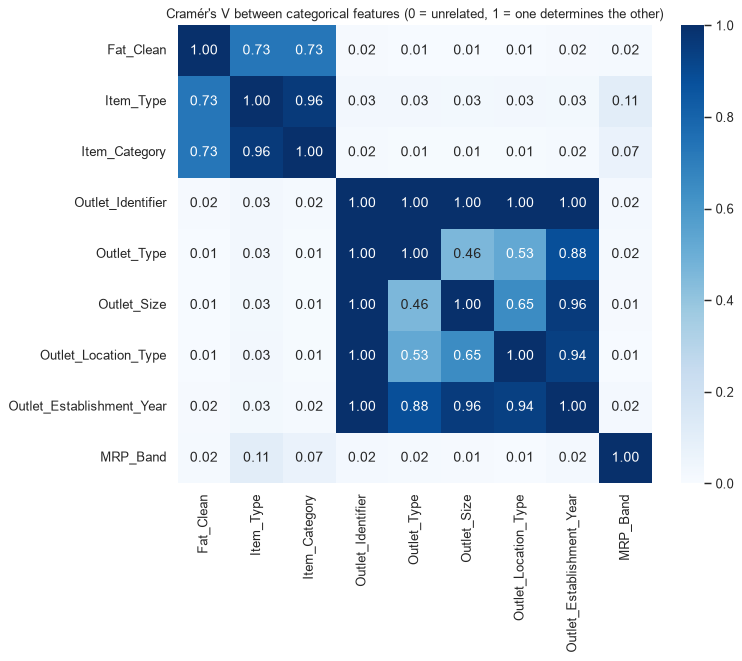

,chi-square,dof,p,Cramér's V
pair,,,,
Outlet_Type x Outlet_Size,"5,380.287",9,0.000,0.459
Outlet_Type x Outlet_Location_Type,"4,725.607",6,0.000,0.527
Item_Type x Fat_Clean,"9,022.408",30,0.000,0.728
Item_Type x Item_Category,"15,704.349",30,0.000,0.960
Item_Type x Outlet_Type,21.358,45,0.999,0.029
MRP_Band x Outlet_Type,8.561,9,0.479,0.018


In [26]:
cats = ["Fat_Clean", "Item_Type", "Item_Category", "Outlet_Identifier", "Outlet_Type", "Outlet_Size",
        "Outlet_Location_Type", "Outlet_Establishment_Year", "MRP_Band"]
d = pd.DataFrame({c: with_missing(df[c]).to_numpy() for c in cats})
v = pd.DataFrame([[cramers_v(d[a], d[b]) for b in cats] for a in cats], index=cats, columns=cats)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(v, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Cramér's V between categorical features (0 = unrelated, 1 = one determines the other)")
plt.show()

rows = []
for a, b in [("Outlet_Type", "Outlet_Size"), ("Outlet_Type", "Outlet_Location_Type"), ("Item_Type", "Fat_Clean"),
             ("Item_Type", "Item_Category"), ("Item_Type", "Outlet_Type"), ("MRP_Band", "Outlet_Type")]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(d[a], d[b]))
    rows.append({"pair": f"{a} x {b}", "chi-square": chi2, "dof": dof, "p": p, "Cramér's V": cramers_v(d[a], d[b])})
pd.DataFrame(rows).set_index("pair")

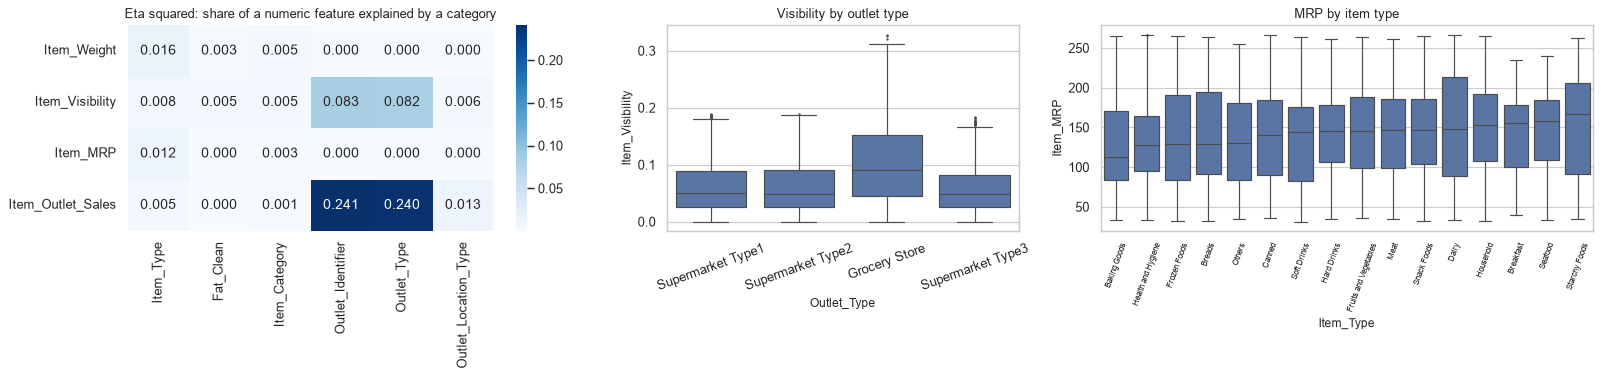

Item_Visibility by Outlet_Type: ANOVA p = 4.59e-158, Kruskal-Wallis p = 4.02e-75, eta squared = 0.082
Item_MRP by Item_Type: ANOVA p = 6.51e-16, Kruskal-Wallis p = 5.31e-16, eta squared = 0.012
Item_Weight by Item_Type: ANOVA p = 7.11e-17, Kruskal-Wallis p = 1.76e-16, eta squared = 0.016


In [27]:
num = ["Item_Weight", "Item_Visibility", "Item_MRP", TARGET]
cats = ["Item_Type", "Fat_Clean", "Item_Category", "Outlet_Identifier", "Outlet_Type", "Outlet_Location_Type"]
eta = pd.DataFrame([[eta_squared(df[n].dropna(), df.loc[df[n].notna(), c].astype(str)) for c in cats] for n in num], index=num, columns=cats)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1.4]})
sns.heatmap(eta, annot=True, fmt=".3f", cmap="Blues", ax=axes[0])
axes[0].set_title("Eta squared: share of a numeric feature explained by a category")
sns.boxplot(data=df, x="Outlet_Type", y="Item_Visibility", ax=axes[1], color="C0", fliersize=1)
axes[1].set_title("Visibility by outlet type"); axes[1].tick_params(axis="x", rotation=20)
order = df.groupby("Item_Type")["Item_MRP"].median().sort_values().index
sns.boxplot(data=df, x="Item_Type", y="Item_MRP", order=order, ax=axes[2], color="C0", fliersize=1)
axes[2].set_title("MRP by item type"); axes[2].tick_params(axis="x", rotation=70, labelsize=7)
plt.tight_layout(); plt.show()
for n, c in [("Item_Visibility", "Outlet_Type"), ("Item_MRP", "Item_Type"), ("Item_Weight", "Item_Type")]:
    t = group_tests(df[n].dropna(), df.loc[df[n].notna(), c])
    print(f"{n} by {c}: ANOVA p = {t['ANOVA p']:.3g}, Kruskal-Wallis p = {t['Kruskal-Wallis p']:.3g}, eta squared = {t['eta squared']:.3f}")

**What this shows:**
- **The numeric features are almost unrelated to each other:** every correlation is below 0.08 in size. Each carries its own information, with no redundancy.
- **The store features are nested.**
  - Outlet type is tied to store size (Cramér's V 0.46) and location (0.53).
  - All of these describe the same 10 stores, so `Outlet_Identifier` already contains them.
- **Item type nearly decides the category** (V 0.96) and the fat label (0.73; household products are always Non-Edible).
- **Every store stocks the same mix of products and prices:** item type × store type V = 0.03 (p = 0.999); price band × store type V = 0.02 (p = 0.48). That is good: store effects and product effects do not mix.
- **Visibility depends on the store type** (η² 0.08). Grocery stores give each product a bigger shelf share, because they carry fewer products.

## 9. Multivariate analysis
Several variables at once:
- a pair plot
- the sales-vs-price line in each store
- a formal test that stores have different slopes
- mean-sales heatmaps
- a full linear model with drop-one F-tests (which feature blocks matter jointly)
- multicollinearity (VIF)
- PCA

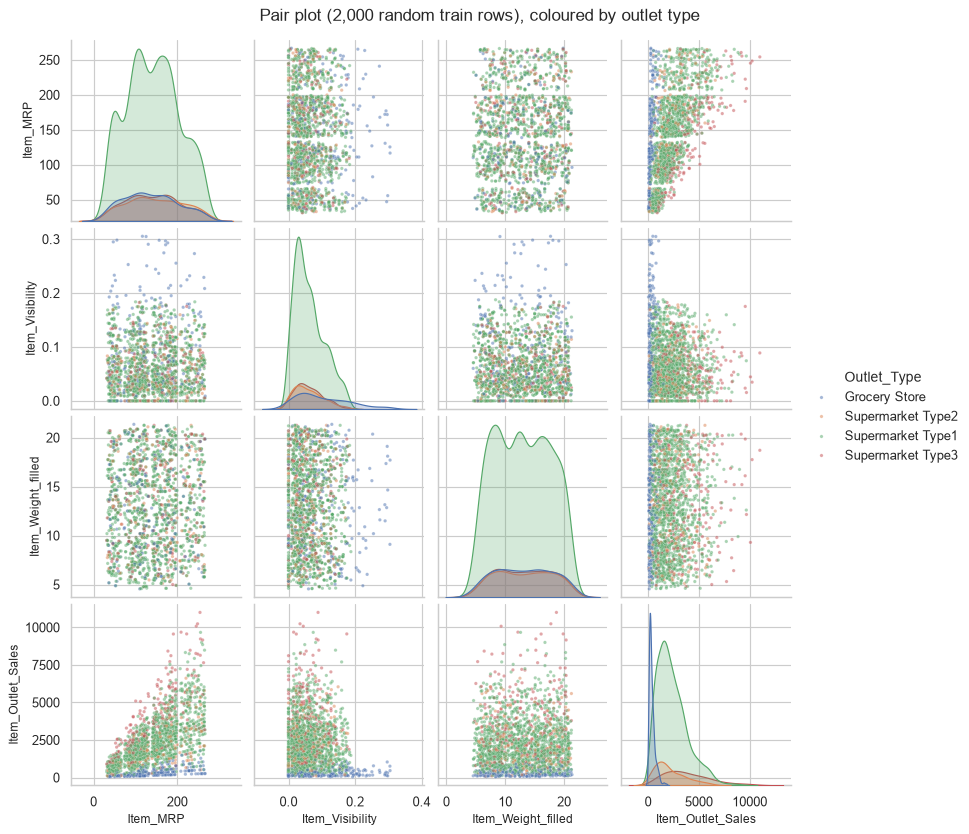

In [28]:
sample = df.dropna(subset=["Item_Weight_filled"]).sample(2000, random_state=0)
g = sns.pairplot(sample, vars=["Item_MRP", "Item_Visibility", "Item_Weight_filled", TARGET], hue="Outlet_Type",
                 plot_kws={"s": 8, "alpha": 0.5}, diag_kind="kde", height=2.4)
g.fig.suptitle("Pair plot (2,000 random train rows), coloured by outlet type", y=1.02)
plt.show()

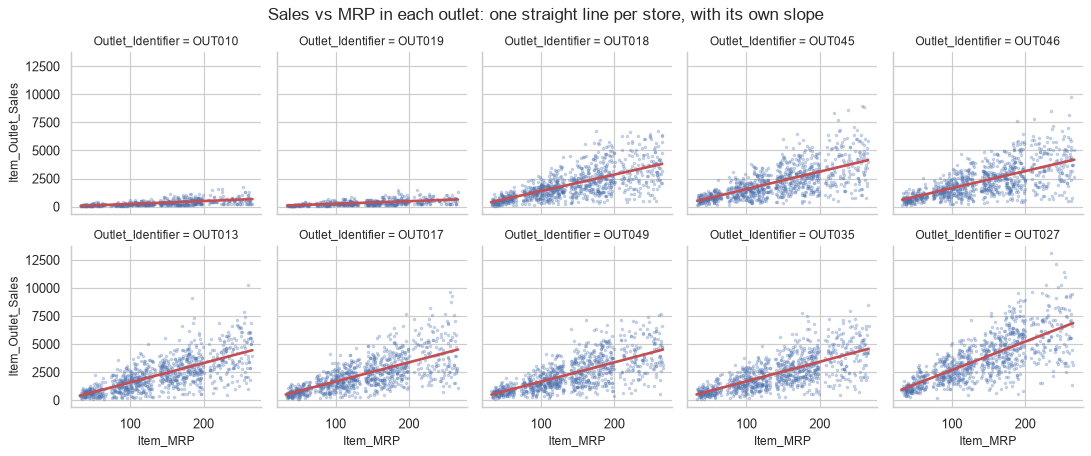

,type,rows,slope (sales per unit of MRP),intercept,R squared,slope p
outlet,,,,,,
OUT019,Grocery Store,528,2.331,14.453,0.327,0.000
OUT010,Grocery Store,555,2.604,-27.192,0.357,0.000
OUT018,Supermarket Type2,928,14.619,-75.708,0.448,0.000
OUT046,Supermarket Type1,930,15.232,113.987,0.417,0.000
OUT045,Supermarket Type1,929,15.584,-4.153,0.441,0.000
OUT017,Supermarket Type1,926,17.067,-38.757,0.475,0.000
OUT049,Supermarket Type1,930,17.165,-59.809,0.489,0.000
OUT013,Supermarket Type1,932,17.236,-138.643,0.500,0.000
OUT035,Supermarket Type1,930,17.365,-46.436,0.482,0.000


In [29]:
order = df.groupby("Outlet_Identifier")[TARGET].mean().sort_values().index
g = sns.lmplot(data=df, x="Item_MRP", y=TARGET, col="Outlet_Identifier", col_wrap=5, height=2.6, col_order=order,
               scatter_kws={"s": 4, "alpha": 0.25}, line_kws={"color": "C3"}, ci=None)
g.fig.suptitle("Sales vs MRP in each outlet: one straight line per store, with its own slope", y=1.03)
plt.show()
rows = []
for outlet, d in df.groupby("Outlet_Identifier"):
    fit = stats.linregress(d["Item_MRP"], d[TARGET])
    rows.append({"outlet": outlet, "type": d["Outlet_Type"].iat[0], "rows": len(d), "slope (sales per unit of MRP)": fit.slope,
                 "intercept": fit.intercept, "R squared": fit.rvalue ** 2, "slope p": fit.pvalue})
pd.DataFrame(rows).set_index("outlet").sort_values("slope (sales per unit of MRP)")

In [30]:
y = df[TARGET].to_numpy()
outlet = pd.get_dummies(df["Outlet_Identifier"], dtype=float).to_numpy()
mrp = df[["Item_MRP"]].to_numpy()
tss = ((y - y.mean()) ** 2).sum()
rss_shared, k_shared = ols_rss(np.hstack([outlet, mrp]), y)           # each outlet its own level, one shared slope
rss_own, k_own = ols_rss(np.hstack([outlet, outlet * mrp]), y)        # each outlet its own level and slope
F = ((rss_shared - rss_own) / (k_own - k_shared)) / (rss_own / (len(y) - k_own))
print(f"R squared, outlet levels + one shared MRP slope: {1 - rss_shared / tss:.4f}")
print(f"R squared, outlet levels + one slope per outlet:  {1 - rss_own / tss:.4f}")
print(f"nested F-test (H0: one slope fits every outlet): F = {F:.1f}, p = {stats.f.sf(F, k_own - k_shared, len(y) - k_own):.1e}")

R squared, outlet levels + one shared MRP slope: 0.5632
R squared, outlet levels + one slope per outlet:  0.6072
nested F-test (H0: one slope fits every outlet): F = 105.8, p = 1.5e-188


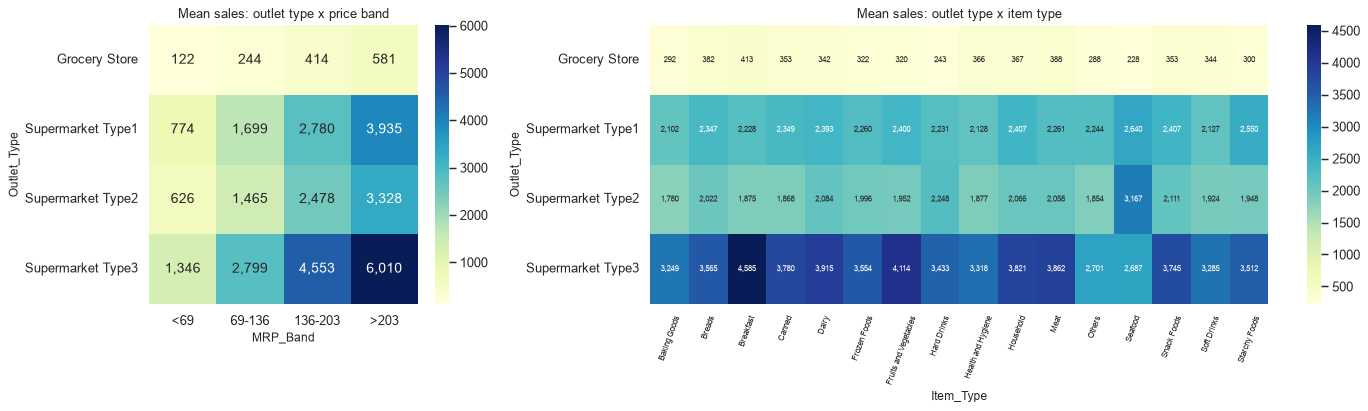

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 2.3]})
sns.heatmap(df.pivot_table(index="Outlet_Type", columns="MRP_Band", values=TARGET, aggfunc="mean", observed=True),
            annot=True, fmt=",.0f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Mean sales: outlet type x price band")
sns.heatmap(df.pivot_table(index="Outlet_Type", columns="Item_Type", values=TARGET, aggfunc="mean"),
            annot=True, fmt=",.0f", cmap="YlGnBu", ax=axes[1], annot_kws={"size": 7})
axes[1].set_title("Mean sales: outlet type x item type")
axes[1].tick_params(axis="x", rotation=70, labelsize=7)
plt.tight_layout(); plt.show()

In [32]:
d = df.dropna(subset=["Item_Weight_filled"])
y = d[TARGET].to_numpy()
outlet_all = pd.get_dummies(d["Outlet_Identifier"], dtype=float)
blocks = {
    "outlet x MRP (level + slope per outlet)": np.hstack([outlet_all.iloc[:, 1:].to_numpy(), outlet_all.to_numpy() * d[["Item_MRP"]].to_numpy()]),
    "ID_Number (2-harmonic wave, period 20)": np.column_stack([f(2 * np.pi * h * d["ID_Number"] / 20) for h in (1, 2) for f in (np.cos, np.sin)]),
    "Item_Type": pd.get_dummies(d["Item_Type"], drop_first=True, dtype=float).to_numpy(),
    "Fat_Clean": pd.get_dummies(d["Fat_Clean"], drop_first=True, dtype=float).to_numpy(),
    "Item_Visibility": d[["Item_Visibility"]].to_numpy(),
    "Item_Weight": d[["Item_Weight_filled"]].to_numpy(),
}
ones = np.ones((len(y), 1))
tss = ((y - y.mean()) ** 2).sum()
full_rss, full_k = ols_rss(np.hstack([ones] + list(blocks.values())), y)
rows = []
for name in blocks:
    rss, k = ols_rss(np.hstack([ones] + [b for n, b in blocks.items() if n != name]), y)
    F = ((rss - full_rss) / (full_k - k)) / (full_rss / (len(y) - full_k))
    rows.append({"drop this block": name, "R squared without it": 1 - rss / tss, "R squared lost": (rss - full_rss) / tss,
                 "partial F": F, "p": stats.f.sf(F, full_k - k, len(y) - full_k)})
print(f"full linear model with every block: R squared = {1 - full_rss / tss:.4f} ({len(y):,} rows, {full_k} parameters)")
pd.DataFrame(rows).set_index("drop this block").sort_values("R squared lost", ascending=False)

full linear model with every block: R squared = 0.6126 (8,519 rows, 42 parameters)


,R squared without it,R squared lost,partial F,p
drop this block,,,,
outlet x MRP (level + slope per outlet),0.026,0.586,675.152,0.000
"ID_Number (2-harmonic wave, period 20)",0.608,0.005,27.472,0.000
Item_Type,0.612,0.000,0.410,0.973
Fat_Clean,0.613,0.000,1.987,0.159
Item_Visibility,0.613,0.000,0.700,0.403
Item_Weight,0.613,0.000,0.083,0.773


,VIF (1 = no overlap; above 5 to 10 = a problem)
Item_Weight_filled,1.001
Item_Visibility,1.006
Item_MRP,1.001
Outlet_Age,1.006


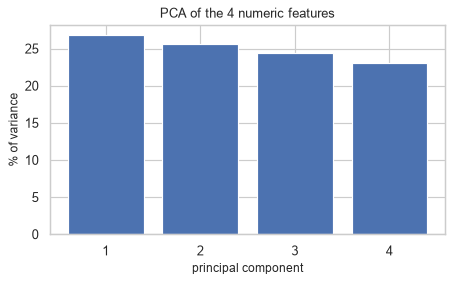

,Item_Weight_filled,Item_Visibility,Item_MRP,Outlet_Age
PC1,0.025,0.704,-0.046,0.709
PC2,0.721,-0.060,0.686,0.078
PC3,-0.652,0.203,0.719,-0.132
PC4,-0.233,-0.678,0.107,0.689


In [33]:
num = df[["Item_Weight_filled", "Item_Visibility", "Item_MRP", "Outlet_Age"]].dropna()
vif = {}
for col in num.columns:
    others = np.column_stack([np.ones(len(num)), num.drop(columns=col).to_numpy()])
    rss, _ = ols_rss(others, num[col].to_numpy())
    vif[col] = 1 / (rss / ((num[col] - num[col].mean()) ** 2).sum())
display(pd.Series(vif).to_frame("VIF (1 = no overlap; above 5 to 10 = a problem)"))

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
pca = PCA().fit(StandardScaler().fit_transform(num))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(range(1, 5), pca.explained_variance_ratio_ * 100, color="C0")
ax.set_xticks(range(1, 5)); ax.set_xlabel("principal component"); ax.set_ylabel("% of variance")
ax.set_title("PCA of the 4 numeric features")
plt.show()
pd.DataFrame(pca.components_, columns=num.columns, index=[f"PC{i}" for i in range(1, 5)])

**What this shows:**
- **One line per store:**
  - Within each store, sales rise in a straight line with MRP.
  - The slope differs by store: about 2.3 to 2.6 in grocery stores, 14.6 in Type2, 15.2 to 17.4 in Type1, and 25.3 in Type3.
  - The slope is roughly 'units sold per product' in that store.
- **The interaction F-test proves the slopes differ:** F = 106, p ≈ 10⁻¹⁸⁸. One slope per store lifts R² from 0.563 to 0.607.
- **In the full linear model (R² 0.613):**
  - Dropping store × price loses 0.586 of R²: almost everything.
  - The id-number wave is the only other block that matters (partial F = 27.5, p ≈ 0).
  - Item type, fat, visibility and weight add nothing (p = 0.16 to 0.97).
- **No multicollinearity:** VIF ≈ 1.00 for every numeric feature.
- **PCA spreads the variance evenly** (27%, 26%, 24%, 23%): the numeric features are close to independent.

**Decision:** build the model around store × price plus the id wave, and leave out the other product columns.

## 10. Deep dives: the structures that shaped the model
Three patterns found while modelling, examined with the same statistical care:
1. **Sales are whole units × price.**
2. **The listed MRP is a noisy copy of a hidden true price** on a 0.6658 grid.
3. **The number at the end of the product id moves sales in a wave.**

### 10.1 Units sold = sales / MRP

mean    var   min    max  dispersion (var / mean; Poisson = 1)
Outlet_Type       Outlet_Identifier                                                                 
Grocery Store     OUT010             2.383  1.916 0.964  7.761                                 0.804
                  OUT019             2.445  1.961 0.952  7.914                                 0.802
Supermarket Type1 OUT013            16.001 52.891 1.954 49.159                                 3.305
                  OUT017            16.660 51.912 1.974 44.477                                 3.116
                  OUT035            16.974 53.390 1.969 44.000                                 3.145
                  OUT045            15.582 48.363 1.979 39.893                                 3.104
                  OUT046            16.191 52.065 1.986 42.503                                 3.216
                  OUT049            16.630 50.141 1.986 45.287                                 3.015
Supermarket Type2 OUT018            13.852 41.553 1.938 38.346                                 3.000
Supermarket Type3 OUT027            26.609 90.325 2.995 56.845                                 3.395

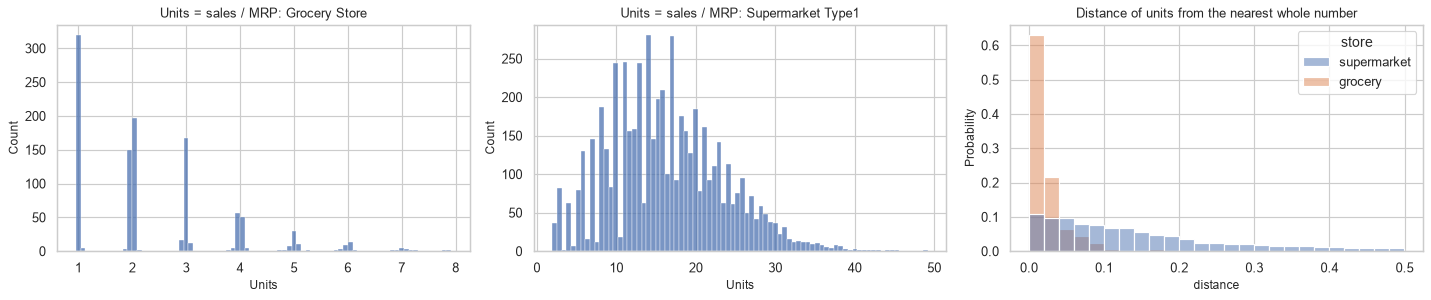

In [34]:
df["Units"] = df[TARGET] / df["Item_MRP"]
units = df.groupby(["Outlet_Type", "Outlet_Identifier"])["Units"].agg(["mean", "var", "min", "max"])
units["dispersion (var / mean; Poisson = 1)"] = units["var"] / units["mean"]
display(units)
fig, axes = plt.subplots(1, 3, figsize=(17, 3.7))
for ax, t in zip(axes[:2], ["Grocery Store", "Supermarket Type1"]):
    sns.histplot(df.loc[df.Outlet_Type == t, "Units"], bins=80, ax=ax, color="C0")
    ax.set_title(f"Units = sales / MRP: {t}")
frac = (df["Units"] - df["Units"].round()).abs()
sns.histplot(data=df.assign(distance=frac, store=np.where(df.Outlet_Type == "Grocery Store", "grocery", "supermarket")),
             x="distance", hue="store", bins=25, stat="probability", common_norm=False, ax=axes[2])
axes[2].set_title("Distance of units from the nearest whole number")
plt.tight_layout(); plt.show()

**What this shows:**
- **Units = sales ÷ MRP:** about 2.4 per product in grocery stores, 14 to 17 in Type1 and Type2 supermarkets, and 27 in OUT027.
- **Grocery units sit almost on whole numbers**, while supermarket rows are blurred (section 10.2 explains why: the MRP is noisy).
- **Compared with a Poisson count** (variance = mean):
  - grocery stores are **under-dispersed** (variance/mean 0.80)
  - supermarkets are **over-dispersed** (3.0 to 3.4)

**Decision:** model units as counts with a Poisson GLM, as v4 and v5 do.

### 10.2 The hidden true price and the noise in `Item_MRP`

In [35]:
s = df[TARGET]
k = s / 0.6658
values = np.sort(s.unique())
print(f"distinct sales values: {s.nunique():,} of {len(s):,} rows; rows sharing their exact value with another row: {s.duplicated(keep=False).mean():.0%}")
print(f"smallest gaps between distinct sales values: {np.round(np.sort(np.diff(values))[:5], 4)}")
print(f"largest distance of sales / 0.6658 from a whole number: {np.abs(k - k.round()).max():.1e}")

prices = models.item_prices(df["Item_Identifier"], df["Item_MRP"], s)      # learned from train rows only
df["True_Price"] = df["Item_Identifier"].map(prices)
df["Units_True"] = s / df["True_Price"]
df["MRP_Noise"] = (df["Item_MRP"] - df["True_Price"]).round(1)
print(f"products with a recovered true price: {len(prices):,} of {df.Item_Identifier.nunique():,}")
print(f"units (= sales / true price) are whole numbers in every row: {np.allclose(df.Units_True, df.Units_True.round())}")
df.loc[df.Item_Identifier == "FDP04", ["Outlet_Identifier", "Item_MRP", TARGET, "True_Price", "Units_True", "MRP_Noise"]]

distinct sales values: 3,493 of 8,523 rows; rows sharing their exact value with another row: 82%
smallest gaps between distinct sales values: [0.6658 0.6658 0.6658 0.6658 0.6658]
largest distance of sales / 0.6658 from a whole number: 3.6e-12
products with a recovered true price: 1,559 of 1,559
units (= sales / true price) are whole numbers in every row: True


,Outlet_Identifier,Item_MRP,Item_Outlet_Sales,True_Price,Units_True,MRP_Noise
1375,OUT045,65.217,958.752,63.917,15.000,1.300
1894,OUT049,62.717,958.752,63.917,15.000,-1.200
2592,OUT018,62.517,447.418,63.917,7.000,-1.400
4624,OUT027,62.017,"1,534.003",63.917,24.000,-1.900
5792,OUT046,64.717,"1,022.669",63.917,16.000,0.800


MRP noise: 41 distinct values from -2.0 to +2.0, mean +0.015, sd 1.195 (uniform over those values: sd 1.183)
each value appears 166 to 251 times (about 208 expected); the end values -2.0 and +2.0 appear 217 and 215 times
chi-square goodness of fit (H0: all 41 values equally likely): chi2 = 59.6, p = 0.02
do units depend on the noise? ANOVA F = 1.03, p = 0.42; Spearman rho = -0.007, p = 0.53
test file (features only): largest |test MRP - true price| = 2.000 (the rule says at most 2)


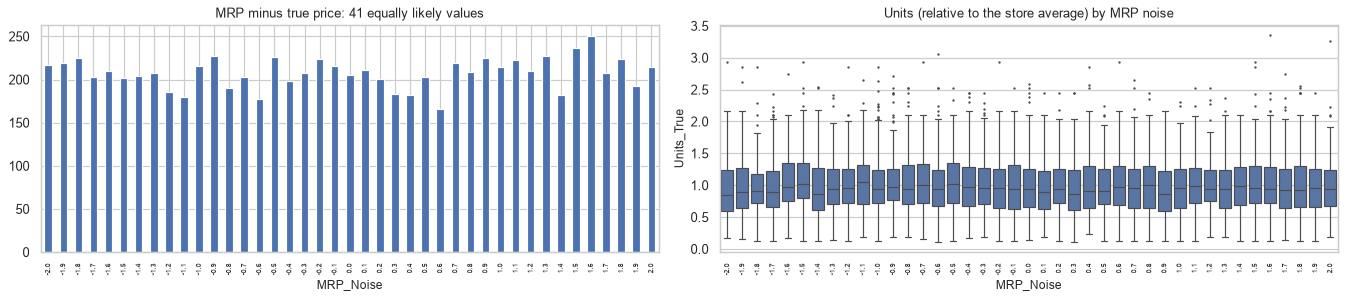

In [36]:
noise = df["MRP_Noise"]
counts = noise.value_counts().sort_index()
gof = stats.chisquare(counts.to_numpy())
print(f"MRP noise: {counts.size} distinct values from {noise.min():+.1f} to {noise.max():+.1f}, mean {noise.mean():+.3f}, "
      f"sd {noise.std():.3f} (uniform over those values: sd {np.sqrt((41 ** 2 - 1) / 12) * 0.1:.3f})")
print(f"each value appears {counts.min()} to {counts.max()} times (about {len(noise) / counts.size:.0f} expected); "
      f"the end values -2.0 and +2.0 appear {counts.iat[0]} and {counts.iat[-1]} times")
print(f"chi-square goodness of fit (H0: all {counts.size} values equally likely): chi2 = {gof.statistic:.1f}, p = {gof.pvalue:.2f}")

ratio = df["Units_True"] / df.groupby("Outlet_Identifier")["Units_True"].transform("mean")
anova = stats.f_oneway(*[ratio[noise == v].to_numpy() for v in counts.index])
rho = stats.spearmanr(noise, ratio)
print(f"do units depend on the noise? ANOVA F = {anova.statistic:.2f}, p = {anova.pvalue:.2f}; "
      f"Spearman rho = {rho.statistic:+.3f}, p = {rho.pvalue:.2f}")

test_noise = te["Item_MRP"] - te["Item_Identifier"].map(prices)
print(f"test file (features only): largest |test MRP - true price| = {test_noise.abs().max():.3f} (the rule says at most 2)")

fig, axes = plt.subplots(1, 2, figsize=(16, 3.7))
counts.plot.bar(ax=axes[0], color="C0")
axes[0].set_title("MRP minus true price: 41 equally likely values"); axes[0].tick_params(axis="x", labelsize=6)
sns.boxplot(x=noise.astype(str), y=ratio, order=[str(v) for v in counts.index], ax=axes[1], color="C0", fliersize=1)
axes[1].set_title("Units (relative to the store average) by MRP noise")
axes[1].tick_params(axis="x", labelsize=6, rotation=90)
plt.tight_layout(); plt.show()

**What this shows (the explicit rule):**
- **Every sale is a whole multiple of 0.6658.** Only 3,493 distinct values appear, 82% of rows share their exact value with another row, and the gaps between values are exactly 0.6658.
- **Each product has one true price on that grid,** recovered for all 1,559 products from train alone. With it, **units are whole numbers in every row.** For example, FDP04 sold exactly 15 units in two stores whose MRPs read 65.22 and 62.72.
- **The MRP noise:**
  - `Item_MRP` = true price + noise, with 41 values from -2.0 to +2.0.
  - Each value appears 166 to 251 times (about 208 expected), and the end values are not rarer (217 and 215).
  - Its standard deviation (1.195) matches an even spread (1.183).
  - A strict χ² test (p = 0.02) finds the counts a little more uneven than pure chance, so 'evenly spread' is a close approximation, not an exact law.
- **Units ignore the noise:** ANOVA p = 0.42, Spearman ρ = -0.007. The noise carries no information about sales.
- **The test file follows the rule:** every test MRP lies within **exactly 2.000** of the true price learned from train.

**Decision (v5):** use the recovered true price instead of the noisy MRP.

### 10.3 The id-number wave

ANOVA of the ratio by id number (H0: the number does not matter): F = 3.31, p = 2.8e-16
lag-1 autocorrelation of the 60 per-number means: 0.58
periodogram: one sine wave explains up to 42% of the per-number variation, at period 19.4


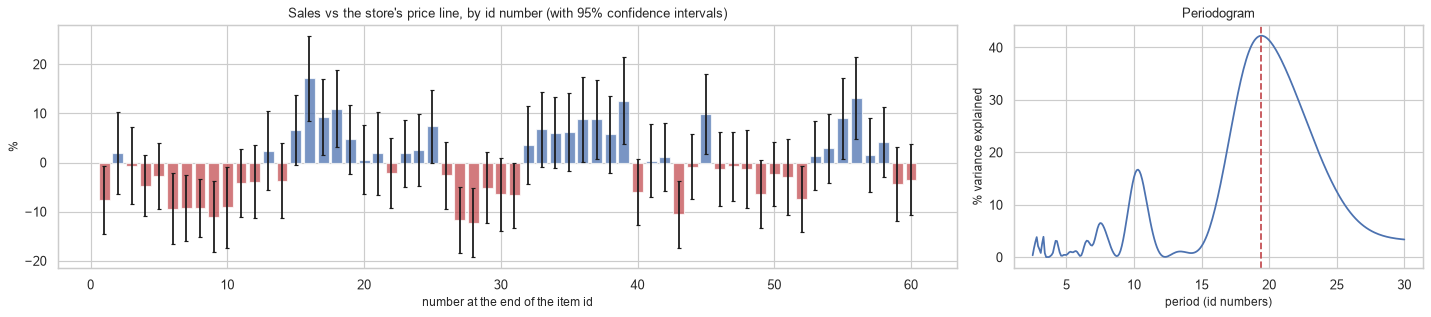

correlation of each category's curve with the overall curve: {'Drinks': 0.82, 'Food': 0.93, 'Non-Consumable': 0.69}


In [37]:
line = models.PerOutletLinear().fit(df, df[TARGET])
df["Ratio"] = df[TARGET] / line.predict(df) - 1            # sales relative to the store's own price line
by_number = df.groupby("ID_Number")["Ratio"].agg(["mean", "std", "size"])
by_number["ci95"] = 1.96 * by_number["std"] / np.sqrt(by_number["size"])
anova = stats.f_oneway(*[g.to_numpy() for _, g in df.groupby("ID_Number")["Ratio"]])
print(f"ANOVA of the ratio by id number (H0: the number does not matter): F = {anova.statistic:.2f}, p = {anova.pvalue:.1e}")
print(f"lag-1 autocorrelation of the 60 per-number means: {by_number['mean'].autocorr(lag=1):.2f}")


def sine_share(t, m, period):
    """Share of the variance of m explained by one sine wave of the given period."""
    basis = np.c_[np.cos(2 * np.pi * t / period), np.sin(2 * np.pi * t / period)]
    fit = basis @ np.linalg.lstsq(basis, m, rcond=None)[0]
    return 1 - np.sum((m - fit) ** 2) / np.sum(m ** 2)


t = by_number.index.to_numpy(dtype=float)
m = by_number["mean"].to_numpy() - by_number["mean"].mean()
periods = np.arange(2.5, 30.01, 0.1)
share = np.array([sine_share(t, m, p) for p in periods])
print(f"periodogram: one sine wave explains up to {share.max():.0%} of the per-number variation, at period {periods[share.argmax()]:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(17, 3.9), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].bar(by_number.index, by_number["mean"] * 100, yerr=by_number["ci95"] * 100, capsize=1.5, alpha=0.75,
            color=np.where(by_number["mean"] >= 0, "C0", "C3"))
axes[0].set_title("Sales vs the store's price line, by id number (with 95% confidence intervals)")
axes[0].set_xlabel("number at the end of the item id"); axes[0].set_ylabel("%")
axes[1].plot(periods, share * 100, color="C0"); axes[1].axvline(periods[share.argmax()], color="C3", ls="--")
axes[1].set_title("Periodogram"); axes[1].set_xlabel("period (id numbers)"); axes[1].set_ylabel("% variance explained")
plt.tight_layout(); plt.show()

curves = df.groupby(["ID_Number", "Item_Category"])["Ratio"].mean().unstack()
print("correlation of each category's curve with the overall curve:", curves.corrwith(by_number["mean"]).round(2).to_dict())

**What this shows:**
- **The number at the end of the product id moves sales by about -12% to +17%** around the store's price line.
- **ANOVA rejects 'the number does not matter'** (F = 3.31, p ≈ 10⁻¹⁶).
- **Neighbouring numbers move together** (lag-1 autocorrelation 0.58).
- **It is a wave:**
  - The periodogram peaks at a period of about **19.4**, where one sine wave explains 42% of the per-number variation.
  - A smaller peak near 10 is the wave's second harmonic.
  - That's why the model uses two harmonics with period about 20.
- **It is shared by every category:** each category's curve correlates with the overall curve at 0.93 (food), 0.82 (drinks) and 0.69 (non-consumables).

### 10.4 After the store's price line, does anything else matter?

In [38]:
checks = {"ID_Number": df["ID_Number"], "Item_Type": df["Item_Type"], "Fat_Clean": df["Fat_Clean"],
          "Item_Category": df["Item_Category"], "ID_Letter": df["ID_Letter"],
          "visibility decile": pd.qcut(df["Item_Visibility"].rank(method="first"), 10, labels=False),
          "weight decile": pd.qcut(df["Item_Weight_filled"].rank(method="first"), 10, labels=False),
          "zero visibility": df["Item_Visibility"].eq(0)}
pd.DataFrame({name: group_tests(df["Ratio"], g) for name, g in checks.items()}).T[
    ["groups", "ANOVA F", "ANOVA p", "Kruskal-Wallis p", "eta squared"]].sort_values("ANOVA p")

,groups,ANOVA F,ANOVA p,Kruskal-Wallis p,eta squared
ID_Number,60.000,3.314,0.000,0.000,0.023
ID_Letter,26.000,1.422,0.079,0.082,0.004
zero visibility,2.000,1.908,0.167,0.186,0.000
Fat_Clean,3.000,0.732,0.481,0.474,0.000
Item_Type,16.000,0.884,0.582,0.661,0.002
weight decile,11.000,0.801,0.628,0.873,0.001
visibility decile,10.000,0.774,0.641,0.346,0.001
Item_Category,3.000,0.019,0.981,0.965,0.000


**What this shows:** once each store's price line is removed, **only the id number still matters** (p ≈ 10⁻¹⁶, η² 0.023).
- The id letter is borderline (p = 0.08).
- Item type, fat, category, visibility, weight and zero visibility are clearly not significant (p ≥ 0.17).

The small 'significant' raw effects in section 7 were therefore confounding with price and store.

## 11. Train vs test: do they come from the same population?
- **Numeric features:** two-sample Kolmogorov-Smirnov tests.
- **Categorical features:** chi-square tests of homogeneity.
- **Overall:** "adversarial validation", i.e. can a classifier tell a train row from a test row?

Only test *features* are used here; there are no test sales.

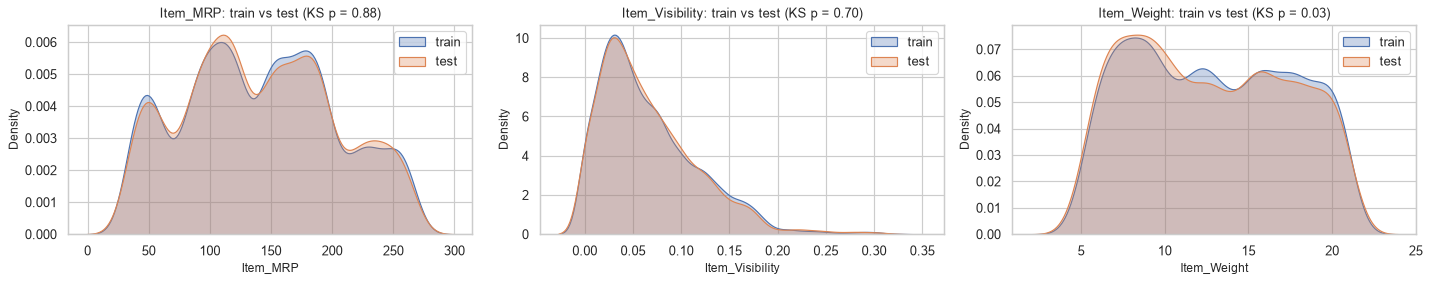

Item_Weight with one value per product (a product's rows share one weight, so rows are not independent): KS p = 1.00


,train mean,test mean,KS statistic,KS p
feature,,,,
Item_MRP,140.993,141.023,0.010,0.884
Item_Visibility,0.066,0.066,0.012,0.699
Item_Weight,12.858,12.696,0.028,0.027


In [39]:
rows = []
fig, axes = plt.subplots(1, 3, figsize=(17, 3.5))
for ax, col in zip(axes, ["Item_MRP", "Item_Visibility", "Item_Weight"]):
    ks = stats.ks_2samp(df[col].dropna(), te[col].dropna())
    rows.append({"feature": col, "train mean": df[col].mean(), "test mean": te[col].mean(), "KS statistic": ks.statistic, "KS p": ks.pvalue})
    sns.kdeplot(df[col].dropna(), ax=ax, label="train", fill=True, alpha=0.3)
    sns.kdeplot(te[col].dropna(), ax=ax, label="test", fill=True, alpha=0.3)
    ax.set_title(f"{col}: train vs test (KS p = {ks.pvalue:.2f})"); ax.legend()
plt.tight_layout(); plt.show()
per_product = stats.ks_2samp(df.groupby("Item_Identifier")["Item_Weight"].first().dropna(),
                             te.groupby("Item_Identifier")["Item_Weight"].first().dropna())
print(f"Item_Weight with one value per product (a product's rows share one weight, so rows are not independent): KS p = {per_product.pvalue:.2f}")
pd.DataFrame(rows).set_index("feature")

In [40]:
rows = []
for col in ["Outlet_Identifier", "Outlet_Type", "Outlet_Size", "Item_Type", "Fat_Clean", "Item_Category", "MRP_Band"]:
    table = pd.concat([with_missing(df[col]).value_counts().rename("train"), with_missing(te[col]).value_counts().rename("test")], axis=1).fillna(0)
    chi2, p, dof, _ = stats.chi2_contingency(table)
    rows.append({"feature": col, "chi-square": chi2, "dof": dof, "p": p})
display(pd.DataFrame(rows).set_index("feature"))
share = te["Outlet_Identifier"].value_counts() / (df["Outlet_Identifier"].value_counts() + te["Outlet_Identifier"].value_counts())
print("share of each outlet's rows that are in test:", share.round(3).sort_index().to_dict())

,chi-square,dof,p
feature,,,
Outlet_Identifier,0.001,9,1.000
Outlet_Type,0.001,3,1.000
Outlet_Size,0.000,3,1.000
Item_Type,12.763,15,0.621
Fat_Clean,0.492,2,0.782
Item_Category,0.499,2,0.779
MRP_Band,3.983,3,0.263


share of each outlet's rows that are in test: {'OUT010': 0.4, 'OUT013': 0.4, 'OUT017': 0.4, 'OUT018': 0.4, 'OUT019': 0.4, 'OUT027': 0.4, 'OUT035': 0.4, 'OUT045': 0.4, 'OUT046': 0.4, 'OUT049': 0.4}


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

both = pd.concat([df.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
both["Weight_or_median"] = both["Item_Weight"].fillna(df["Item_Weight"].median())
cat_cols, num_cols = ["Item_Type", "Fat_Clean", "Outlet_Identifier", "Item_Category"], ["Item_MRP", "Item_Visibility", "Weight_or_median", "ID_Number"]
classifier = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols), ("num", StandardScaler(), num_cols)]),
    LogisticRegression(max_iter=2000))
auc = cross_val_score(classifier, both[cat_cols + num_cols], both["is_test"], cv=5, scoring="roc_auc")
print(f"adversarial validation AUC = {auc.mean():.3f} +- {auc.std():.3f}  (0.5 = train and test are indistinguishable)")

adversarial validation AUC = 0.481 +- 0.010  (0.5 = train and test are indistinguishable)


**What this shows:** train and test come from the same population.
- **Numeric features:**
  - MRP and visibility pass the KS test (p = 0.88 and 0.70).
  - Weight 'fails' on rows (p = 0.03), but that test assumes independent rows. Each product repeats with the same weight, which breaks the assumption.
  - Comparing one value per product gives p = 1.00. Lesson: check a test's assumptions before believing it.
- **Categorical mixes match:** all χ² p ≥ 0.26, and every store has **exactly 40%** of its rows in test.
- **Adversarial validation:** a classifier cannot tell train rows from test rows (AUC 0.48; 0.5 means a coin flip).

So cross-validation on train is a fair stand-in for the test set.

## 12. Summary: what the EDA found and what it led to

| # | Finding | Statistical evidence | What it led to |
|---|---|---|---|
| 1 | Missing values are whole stores (weight: OUT019, OUT027; size: OUT010, OUT017, OUT045) | missing share is 100% or 0% per store | Fill weight from the same product; store identity replaces size |
| 2 | Fat content has 5 spellings; non-consumables carry fat labels | frequency table, crosstab | Merge into Low Fat / Regular / Non-Edible |
| 3 | Sales are right-skewed and not normal | skewness 1.18; four normality tests p ≈ 0 | Predict raw sales (the RMSE scale) with log-link models |
| 4 | Price is the strongest single driver | r = 0.57 (r² = 0.32) | Price in every model |
| 5 | Each store has its own sales-per-price slope | interaction F = 106, p ≈ 10⁻¹⁸⁸; store η² = 0.24 | One line per store (v1 to v3), store × price terms (v4, v5) |
| 6 | Errors grow with price (fan shape) | SD 493 → 2,123 at a constant CV of about 0.6; Levene p ≈ 0 | Weighted least squares; multiplicative GLMs |
| 7 | Units sold are counts with uneven dispersion | variance/mean 0.8 (grocery) to 3.4 (OUT027) | Poisson GLM on units (v4) |
| 8 | The id number moves sales in a wave | ANOVA p ≈ 10⁻¹⁶; periodogram peak at 19.4 (42%) | Two-harmonic Fourier wave (v4) |
| 9 | Sales = whole units × a hidden true price; MRP = true price ± 2 | grid distance 4×10⁻¹²; whole units in every row; noise unrelated to units (p = 0.42) | Use the recovered true price (v5) |
| 10 | Item type, fat, weight and visibility add nothing | partial F p = 0.16 to 0.97; after the store line p ≥ 0.17 | Left out of the final model |
| 11 | Train and test match | KS and χ² p ≥ 0.26 (weight per product); adversarial AUC 0.48 | Trust cross-validation on train |

**The four kinds of analysis in this notebook:**
- **Descriptive (sections 1 to 5):** what the data looks like. Shapes, frequencies, gaps, errors.
- **Diagnostic (sections 6 to 11):** which patterns are real. Every claim above has a test behind it, and two apparent effects were caught as artefacts: the raw item-type effect (confounding with price) and the weight shift (non-independent rows).
- **Predictive:** what can forecast sales. Store × price, the id-number wave, and the true price; nothing else.
- **Prescriptive:** what to do about it. The decisions in the last column, which together give the final model v5 (CV RMSE 1059.4, public 1136.80).